# Consumer Financial Complaints Analysis
### INFO 4360 – Complex Data Analytics

**Team Members:** Rebecca Quaye and Ketty Odero  
**Project:** Consumer Complaint Classification Using Natural Language Processing (NLP)  
**Analysis Path:** Path A – Predictive Classification



## Project Overview

This project explores whether consumer complaint narratives can be used to predict the financial product category associated with a complaint.

We analyze a sample of 5,000 complaints from the Consumer Financial Protection Bureau (CFPB), covering 11 financial product categories between August 2025 and July 2026.

## Research Question

**Can consumer complaint narratives accurately predict the financial product category associated with a complaint?**

## Analysis Approach

Our analysis includes:

1. **Exploratory Data Analysis (EDA):** Examining product distributions, missing values, narrative lengths, and duplicate complaints.
2. **Text Preprocessing:** Cleaning complaint narratives and preparing text for analysis.
3. **Text Mining:** Exploring word frequencies, bigrams, TF-IDF, and product-specific vocabulary.
4. **Sentiment Analysis:** Comparing baseline VADER sentiment scores with an experimental domain-adjusted approach.
5. **Predictive Modeling (Planned):** Using TF-IDF with Logistic Regression, Naive Bayes, and Linear SVM to classify complaints.
6. **LLM Comparison (Planned):** Exploring Claude API classification and comparing its results with traditional machine learning models.

## Project Goal

Our goal is to understand patterns in consumer complaint narratives and investigate whether NLP can help organizations automatically categorize incoming complaints.

---

**Note:** The exploratory and text analyses are part of our Phase 2 development. Predictive modeling and LLM comparisons are planned for Phase 3.

> **Reporting status:** The traditional TF-IDF models have recorded held-out results. Claude-generated category descriptions and the embedding classifier are included as a reproducible, **not-yet-executed extension**; they must not be described as evaluated until the privacy review and API workflow are completed.


## 0. Setup
### 0.1 Imports

In [1]:
# Notebook display, file handling, text patterns, and reproducible project paths
%matplotlib inline
import sys
import os
import re
import json
import time
import hashlib
from pathlib import Path
from collections import Counter

# Locate repository root whether VS Code starts in Notebook/ or the repository root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebook" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
DATA_DIR = PROJECT_ROOT / "Data"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "rebecca_modelling"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Data handling and notebook tables
import numpy as np
import pandas as pd
from IPython.display import display

# Visualization: charts, heatmaps, and word clouds
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# NLP: stopwords, lemmatization, and NLTK language resources
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download(["stopwords", "wordnet"], quiet=True)

# Supervised learning: stratified validation, TF-IDF, and three classifiers
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

# Evaluation: per-class reports, confusion matrices, and cosine similarity
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score)
from sklearn.metrics.pairwise import cosine_similarity

# Claude API and .env credentials (never display secret values); embeddings load on demand
from dotenv import load_dotenv
import anthropic

# Reusable data preparation and sentiment functions from this project
from src.data_utils import load_complaints, missing_values, duplicate_narratives, TEXT_COL
from src.preprocessing import (clean_text, drop_duplicate_narratives, top_terms,
                               distinctive_terms, product_word_matrix, STOPWORDS)
from src.text_analysis import (sentiment_scores, sentiment_label, positive_word_contributions,
                               FINANCE_WORDS)

# Consistent figure styling for presentation and reporting
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95,
              rc={"axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlesize": 12})
MAIN = sns.color_palette("deep")[0]
ACCENT = sns.color_palette("deep")[3]
pd.set_option("display.max_colwidth", 200)
print("Project root:", PROJECT_ROOT)


Project root: /Users/rebeccaquaye/Complex Data Analytics/Project/consumer-financial-complaints


### 0.2 Load the data

In [2]:
# Load the complaint sample. load_complaints reads the CSV, parses the dates and adds
# three helper columns: month, product_short (short product names) and word_count
DATA_PATH = DATA_DIR / "cfpb_complaints_sample_2025-08_to_2026-07.csv"
df = load_complaints(DATA_PATH)

## 1. Data exploration

### 1.1 Size and structure

A quick look at how many complaints we have, the period they cover, and the columns we will use.
Note: the 19 columns include 3 helper columns created by `load_complaints` (`month`, `product_short`, `word_count`).

In [3]:
# Preview the first two rows with every column, to see what each field looks like
df.head(2)

,Date received,Product,Sub-product,Issue,Sub-issue,Consumer complaint narrative,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID,month,product_short,word_count
0,2025-11-03,Mortgage,VA mortgage,Trouble during payment process,Payment process,"b""Summary\n\nShellpoint / XXXX have created a pattern of payment re-aging, unapplied funds, and fabricated fees on my post-discharge mortgage account. Agents repeatedly invoked bankruptcy discla...",Company has responded to the consumer and the CFPB and chooses not to provide a public response,"Shellpoint Partners, LLC",TN,37066,Servicemember,Web,2025-11-03,Closed with explanation,Yes,16983019,2025-11,Mortgage,5058
1,2026-04-27,Debt or credit management,Debt settlement,Didn't provide services promised,NaN,"I am filing a complaint against Affirm regarding a consumer loan used to finance a purchase that was never full delivered. On XX/XX/year>, I entered into a financing agreement with Affirm to purch...",NaN,"Affirm Holdings, Inc",ME,049XX,Older American,Web,2026-04-27,Closed with explanation,Yes,21642170,2026-04,Debt management,351


In [4]:
# --- Dataset size and scope ---
print(f"Rows: {len(df):,}   Columns: {df.shape[1]}")

# Date range covered by the sample (should run Aug 2025 to Jul 2026)
print(f"Complaints received: {df['Date received'].min():%b %d, %Y} to {df['Date received'].max():%b %d, %Y}")

# Number of target classes (products) and how many different companies appear
print(f"Product categories: {df['Product'].nunique()}   Companies: {df['Company'].nunique()}")

# --- Preview: first 5 complaints, showing the key columns only ---
df[["Date received", "product_short", "Issue", "word_count"]].head()

Rows: 5,000   Columns: 19
Complaints received: Aug 01, 2025 to Jul 29, 2026
Product categories: 11   Companies: 626


,Date received,product_short,Issue,word_count
0,2025-11-03,Mortgage,Trouble during payment process,5058
1,2026-04-27,Debt management,Didn't provide services promised,351
2,2026-05-19,Debt management,Confusing or misleading advertising or marketing,275
3,2025-11-29,Debt collection,False statements or representation,242
4,2026-02-09,Credit reporting,Incorrect information on your report,120


### 1.2 Missing values

In [5]:
# Count missing values per column (only columns with at least one gap are listed)
missing_values(df)

,missing_rows,share_missing
Tags,4182,0.836
Company public response,3436,0.687
Sub-issue,1398,0.280
State,38,0.008
ZIP code,10,0.002


The two columns we need, the narrative (input X) and the product (target Y), have **no missing values**, so all 5,000 complaints can be used and no rows are dropped. The gaps are in fields we will not use as model inputs: `Tags` (84% missing) is only filled for older Americans and servicemembers, and `Company public response` (69%) is optional. `Sub-issue` (28%) is blank for issues that have no sub-issues.

### 1.3 Target distribution: our sample vs. the full database

In the full CFPB database one category dominates. We sampled the same number of complaints per product so the model learns every category, not just credit reporting.

In [6]:
# Count complaints by product (the target variable we will predict)
product_counts = df["Product"].value_counts()

product_counts

Product
Debt or credit management                                  455
Debt collection                                            455
Credit reporting or other personal consumer reports        455
Credit card                                                455
Money transfer, virtual currency, or money service         455
Checking or savings account                                455
Mortgage                                                   454
Payday loan, title loan, personal loan, or advance loan    454
Vehicle loan or lease                                      454
Prepaid card                                               454
Student loan                                               454
Name: count, dtype: int64

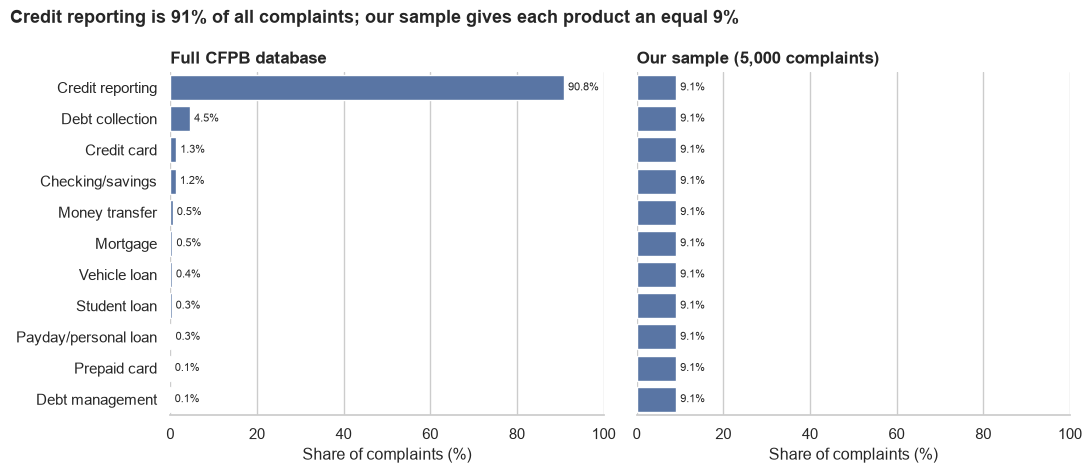

In [7]:
# Product counts shown on the CFPB complaint search page (all complaints, Oct 2026)
database_counts = pd.Series({
    "Credit reporting": 6_341_482, "Debt collection": 317_439, "Credit card": 92_750,
    "Checking/savings": 85_931, "Money transfer": 38_217, "Mortgage": 32_110,
    "Vehicle loan": 24_617, "Student loan": 19_519, "Payday/personal loan": 17_907,
    "Prepaid card": 6_122, "Debt management": 4_243,
})
# Convert counts to % shares so the full database and our sample can be compared on one scale
database_share = database_counts / database_counts.sum() * 100
sample_share = df["product_short"].value_counts(normalize=True) * 100

order = database_share.sort_values().index      # same product order in both panels

shares = pd.DataFrame({"Full CFPB database": database_share,
                       "Our sample (5,000 complaints)": sample_share}).reindex(order[::-1])

# Two side-by-side bar charts: full database (left) vs. our sample (right)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, column in zip(axes, shares.columns):
    sns.barplot(x=shares[column], y=shares.index, color=MAIN, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3, fontsize=8)   # write the % at the end of each bar
    ax.set(xlim=(0, 100), xlabel="Share of complaints (%)", ylabel="", title=column)

fig.suptitle("Credit reporting is 91% of all complaints; our sample gives each product an equal 9%",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
sns.despine(left=True)
plt.tight_layout()
plt.show()

- Our sample is **balanced by design**: 454 or 455 complaints for each of the 11 products (table above).
- The real complaint stream is extremely imbalanced: credit reporting is about 91%, and the six smallest products are each under 0.5%. A model trained on raw data could score 91% accuracy by always guessing "credit reporting" and still be useless for routing.
- Because the sample is balanced, **accuracy is a fair headline metric**, and **macro F1** (which weights every product equally) shows whether small products are handled well.
- For Phase 3: a model trained on balanced data will over-predict small products when used on real traffic. We will note this and consider adjusting for real-world frequencies when interpreting results.

### 1.4 Coverage over time

In [8]:
# Number of complaints received in each month of the sample
per_month = df["month"].value_counts().sort_index()
print(per_month.to_string())

# Smallest count in the month x product table: if it is above 0, every product appears in every month
print(f"\nSmallest product-month cell: {pd.crosstab(df['month'], df['Product']).min().min()} complaints")

month
2025-08    418
2025-09    418
2025-10    418
2025-11    418
2025-12    418
2026-01    418
2026-02    418
2026-03    418
2026-04    418
2026-05    418
2026-06    413
2026-07    407
Freq: M

Smallest product-month cell: 37 complaints


- Every month from August 2025 to May 2026 has 418 complaints; June (413) and July (407) are slightly lower, likely because fewer recent narratives were published before the CFPB stopped publishing narratives in August 2026. Every product appears in every month (the smallest product-month count is 37), so no single month drives the patterns we find.

### 1.5 Complaint Narrative Length

We examine the length of the consumer complaint narratives to understand how much the amount of text varies across complaints.

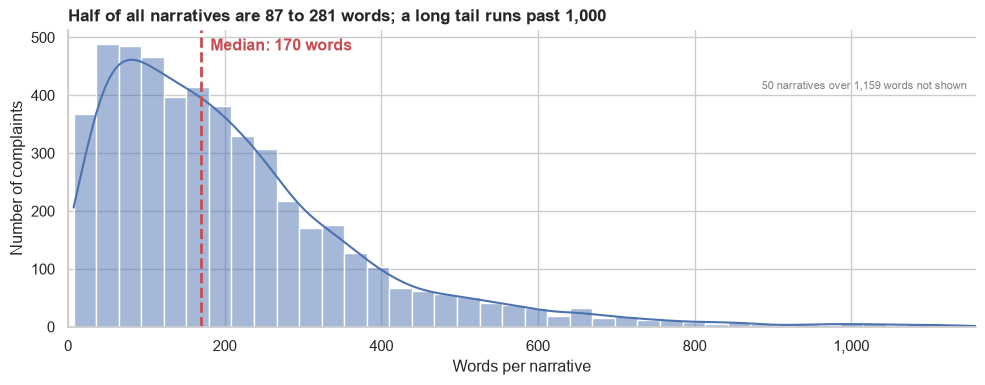

count    5000.0
mean      225.0
std       251.0
min         7.0
25%        87.0
50%       170.0
75%       281.0
max      5058.0
Under 50 words: 12%   Over 500 words: 7%


In [9]:
# Number of words in each narrative (helper column created by load_complaints)
words = df["word_count"]

# Plain (linear) axis: show the chart up to the 99th percentile so the long tail
# doesn't squash the bars; the statistics below still use every complaint
cap = words.quantile(0.99)
shown = words[words <= cap]

fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(shown, bins=40, color=MAIN, kde=True, ax=ax)   # bars = counts, line = smoothed shape
# Dashed line and label at the median
ax.axvline(words.median(), color=ACCENT, linewidth=2, linestyle="--")
ax.text(words.median() + cap * 0.01, ax.get_ylim()[1] * 0.93, f"Median: {words.median():.0f} words",
        color=ACCENT, fontweight="bold")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))   # 1,000 instead of 1000
ax.set(xlim=(0, cap), xlabel="Words per narrative", ylabel="Number of complaints",
       title="Half of all narratives are 87 to 281 words; a long tail runs past 1,000")
# Note on the chart how many long narratives fall outside the plotted range
ax.text(0.99, 0.80, f"{(words > cap).sum()} narratives over {cap:,.0f} words not shown",
        transform=ax.transAxes, ha="right", fontsize=8, color="grey")
sns.despine()
plt.tight_layout()
plt.show()

# Summary statistics on ALL narratives, plus the share of very short and very long ones
print(words.describe().round(0).to_string())
print(f"Under 50 words: {(words < 50).mean():.0%}   Over 500 words: {(words > 500).mean():.0%}")

Complaint narrative lengths are right-skewed, with most complaints containing relatively short narratives and fewer complaints having very long narratives. The median narrative is 170 words, while the mean is higher at 225 words, and the longest runs to 5,058 words. This difference reflects a smaller number of very long complaints: 7% are over 500 words, while 12% are under 50 words.

For readability, the histogram displays narratives up to the 99th percentile. The full dataset, including longer narratives, is retained for the analysis. The variation in narrative length may be important when preprocessing the text and building the classification model.

### 1.6 Data quality: redactions and template letters

In [10]:
# Share of narratives containing CFPB redactions (two or more X's in a row, e.g. XXXX)
has_redaction = df[TEXT_COL].str.contains(r"X{2,}")
print(f"Narratives with redacted text (XXXX): {has_redaction.mean():.0%}")

# Narratives whose text appears more than once (template letters)
dupes = duplicate_narratives(df)
extra_copies = int((dupes["copies"] - 1).sum())   # copies beyond the first one of each letter
print(f"Narratives that appear more than once: {len(dupes)}  ({extra_copies} extra copies)")
dupes.head(5)   # the five most repeated letters

Narratives with redacted text (XXXX): 82%
Narratives that appear more than once: 44  (105 extra copies)


,copies,narrative_start
0,27,There are collection accounts on my report that I believe contain inaccurate information. Under my rights pursuant to 15...
1,13,"You have reported inaccurate and unauthorized accounts on my credit report, which is a violation of the Fair Credit Repo..."
2,7,My rights were violated as a consumer under 15USC1681B and I need them blocked and deleted from my report ASAP...
3,7,I want to stress that I did not give written permission for these specific transactions to be included in my consumer re...
4,5,My credit reports are inaccurate. These inaccuracies are causing creditors to deny me credit. You have the duty to repor...


- **82% of narratives contain CFPB redactions** (`XXXX` for names, account numbers and dates). These are meaningless to a model, so the cleaning step will remove them before counting words.
- **105 rows are exact copies** of 44 template letters, mostly credit reporting disputes citing FCRA sections. If copies land in both the training and test sets, the model is tested on text it has already seen and its score is inflated. We remove the extra copies before modeling, leaving 4,895 unique narratives.

### 1.7 Example narratives (one per product)

In [11]:
# Display one sample complaint narrative per product (random_state fixes the sample so it is reproducible)
sample_complaints = (
    df[["Product", "Consumer complaint narrative"]]
    .groupby("Product")
    .sample(n=1, random_state=42)
    .sort_values("Product")
)

# Print the product and the first 500 characters of its narrative
for _, row in sample_complaints.iterrows():
    print("Product:", row["Product"])
    print("Narrative:", row["Consumer complaint narrative"][:500])
    print("-" * 80)

Product: Checking or savings account
Narrative: On XX/XX/year>2025, a teller at a Chase branch store stole {$1200.00} from my cash deposit while I was having a medical emergency. I am a type XXXX XXXX  and was experiencing XXXX XXXX XXXX  at the time, not feeling well. The teller noticed something was wrong, but instead of helping me, she took advantage of my condition and shorted my deposit. 

I tried filing a complaint with Chase immediately after the incident by calling the fraud department, and again on XX/XX/year>2025. Each time I was to
--------------------------------------------------------------------------------
Product: Credit card
Narrative: - I have been unable to log into my account for almost a year. Since XX/XX/XXXX. - I attempted to log in while on the phone with a Synchrony representative who confirmed that the information I was entering was correct, yet the system continued to reject it ; no technical ticket was opened and no remedy was provided to me outside of a re

The sample complaints vary in length and writing style, but they contain language that provides clues about the financial product involved. Some name the product outright ("my mortgage account", "private student loan", "my vehicle", "Amex giftcard"), while others only point to it through context, such as a company or service name (PayPal for money transfer, Cash App Borrow for a payday loan). The mortgage example is itself about credit reporting of a late payment, so a single complaint can touch more than one product.

This supports the use of text classification for categorizing unlabeled complaints, but it also highlights a potential concern: explicit product words may make some complaints easier to classify. We will examine this further in the modeling phase as part of our leakage and sanity checks.

## 2. Text mining

### 2.1 Preparing the text

Before counting words we (1) keep one copy of each duplicate narrative, so a template letter sent 27 times is not counted 27 times, and (2) clean each narrative with `clean_text` from `src/preprocessing.py`: lower-case, and remove CFPB redactions (`XXXX`), dollar amounts, numbers and punctuation.

For the simple word counts in 2.2 and 2.3 we use a second, stricter cleaning (`clean_for_counts`): lower-case, keep letters only, drop English stopwords and redaction placeholders, and lemmatize ("payments" → "payment"), so that counts group word forms together. These counts run on all 5,000 narratives.

In [12]:
# Remove duplicate template letters, then clean every narrative
text_df = drop_duplicate_narratives(df)                 # keep one copy of each template letter
text_df["clean"] = text_df[TEXT_COL].map(clean_text)   # cleaned text used for TF-IDF and sentiment checks
print(f"Unique narratives used for text mining: {len(text_df):,}")

# Before / after cleaning for one complaint
example = text_df.iloc[3]
print("\nBEFORE:", example[TEXT_COL][:300])
print("\nAFTER: ", example["clean"][:300])

Unique narratives used for text mining: 4,895

BEFORE: I am writing in response to your communication regarding the abovereferenced alleged debt. I dispute this debt in its entirety ( or, if applicable, I dispute the amount you claim is owed ) and request full validation under the Fair Debt Collection Practices Act ( FDCPA ), 15 U.S.C. 1692g.

Please pr

AFTER:  i am writing in response to your communication regarding the abovereferenced alleged debt i dispute this debt in its entirety or if applicable i dispute the amount you claim is owed and request full validation under the fair debt collection practices act fdcpa u s c g please provide in writing the n


In [13]:
# Stricter cleaning for raw word counts (stopwords removed, lemmatized)
stop_words = set(stopwords.words("english"))   # common English words such as "the", "and", "is"
lemmatizer = WordNetLemmatizer()               # reduces words to their base form ("payments" -> "payment")

def clean_for_counts(text):
    # Convert text to lowercase
    text = text.lower()
    
    # Remove numbers and special characters
    text = re.sub(r"[^a-z\s]", " ", text)
    
    # Split text into individual words
    words = text.split()

    # Remove stopwords and redaction placeholders
    words = [
    word for word in words
    if word not in stop_words and not re.fullmatch(r"x+", word)
    ]

    # Lemmatize words
    words = [lemmatizer.lemmatize(word) for word in words]
    
    # Join words back into text
    return " ".join(words)

# Apply stricter cleaning to unique narratives for word-frequency analysis
text_df["clean_narrative"] = text_df[TEXT_COL].apply(clean_for_counts)


### 2.2 Most common words and phrases across all complaints

We start with single words, then move to two-word phrases (bigrams), which carry more meaning.

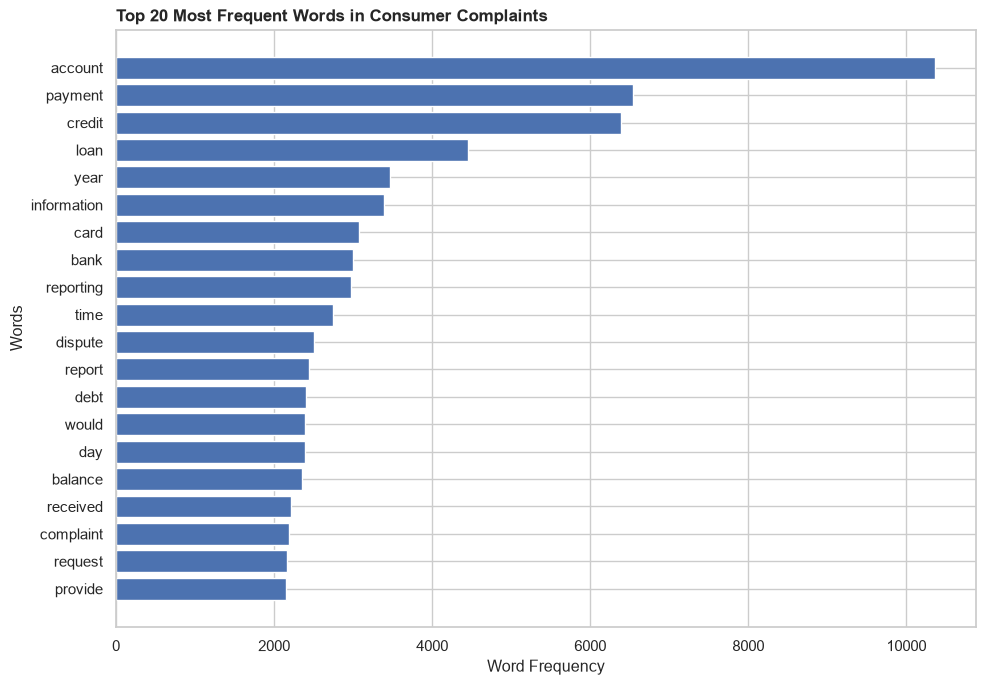

In [14]:
# Count the most common single words across all narratives

# Combine cleaned words from unique complaint narratives
all_words = " ".join(text_df["clean_narrative"]).split()
# Count how often each word appears
word_counts = Counter(all_words)   # Counter maps each word to the number of times it appears

# Get the 20 most common words
top_words = pd.DataFrame(
    word_counts.most_common(20),
    columns=["Word", "Frequency"]
)
# Plot the 20 most frequent words
plt.figure(figsize=(10, 7))

plt.barh(top_words["Word"], top_words["Frequency"])

plt.title("Top 20 Most Frequent Words in Consumer Complaints")
plt.xlabel("Word Frequency")
plt.ylabel("Words")

# Display the most frequent word at the top
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Interpretation

- **Account** is the most frequently used word, followed by **payment**, **credit**, and **loan**. These terms reflect common financial issues discussed in consumer complaints.
- Most of the frequently occurring words are general financial terms that appear across different product categories.
- Although individual words help us understand the main topics in complaints, they may not be enough to distinguish financial products. This is why we also examine bigrams and other text-mining techniques.

**Note:** This analysis uses 4,895 unique complaint narratives after removing duplicates to avoid counting repeated text multiple times.

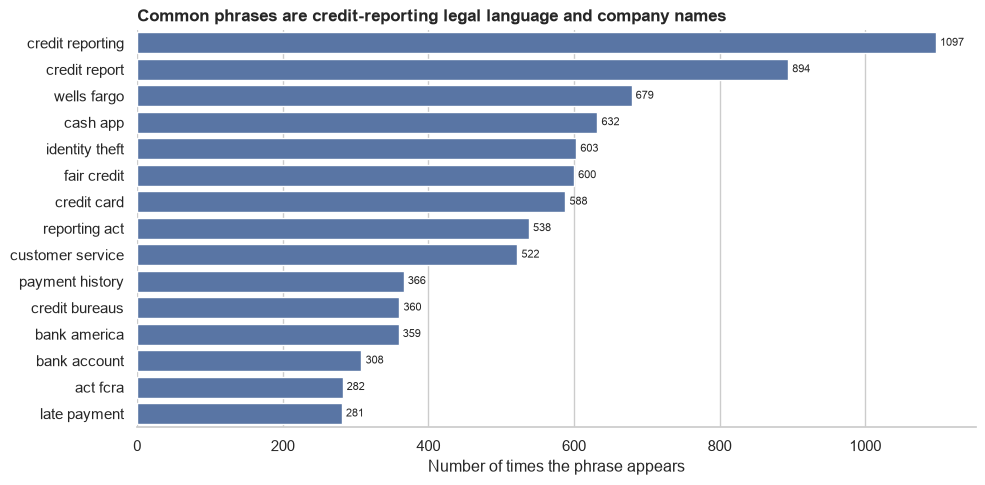

In [15]:
# Top 15 two-word phrases across all complaints
top_phrases = top_terms(text_df["clean"], n=15, ngram_range=(2, 2))   # ngram_range=(2, 2): two-word phrases only

# Horizontal bar chart, most frequent phrase at the top
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=top_phrases, x="count", y="term", color=MAIN, ax=ax)
ax.bar_label(ax.containers[0], padding=3, fontsize=8)   # write the count at the end of each bar
ax.set(xlabel="Number of times the phrase appears", ylabel="",
       title="Common phrases are credit-reporting legal language and company names")
sns.despine(left=True)
plt.tight_layout()
plt.show()

- The two most frequent phrases are "credit reporting" (1,097) and "credit report" (894), and several others ("fair credit", "reporting act", "act fcra") come from **legal language about the Fair Credit Reporting Act**. Consumers in several products, not only credit reporting, quote this law, so these phrases alone will not separate products cleanly.
- **Company names** are among the most common phrases: "wells fargo" (679) and "cash app" (632) rank third and fourth, and "bank america" (359) also appears. A company usually points to a product (Cash App means money transfer), so the model may lean on them. That is useful for routing at one bank, but we will check in Phase 3 that the model is not relying on company names alone.
- "Identity theft" (603 mentions) is a major theme on its own.

### 2.3 The words that distinguish each product

**Raw counts first.** The most frequent words within each product:

In [16]:
# Get the most common words for a product category
def get_top_words_by_product(product, n=10):

    # Select cleaned narratives for the chosen product
    product_text = text_df.loc[
        text_df["Product"] == product, "clean_narrative"
    ]

    # Combine the narratives into individual words
    words = " ".join(product_text).split()

    # Count the words
    word_counts = Counter(words)

    # Return the most frequent words
    return pd.DataFrame(
        word_counts.most_common(n),
        columns=["Word", "Frequency"]
    )


# Get the top 5 words for each product category
product_word_summary = []

# Loop through all 11 financial product categories
for product in text_df["Product"].unique():

    top_words_product = get_top_words_by_product(product, n=5)

    product_word_summary.append({
        "Product": product,
        "Top 5 Words": ", ".join(top_words_product["Word"])
    })

# Display the summary
product_word_summary = pd.DataFrame(product_word_summary)

product_word_summary

,Product,Top 5 Words
0,Mortgage,"payment, mortgage, loan, account, year"
1,Debt or credit management,"account, credit, debt, payment, fee"
2,Debt collection,"account, debt, credit, reporting, collection"
3,Credit reporting or other personal consumer reports,"account, credit, reporting, information, report"
4,Credit card,"credit, account, card, payment, charge"
5,"Money transfer, virtual currency, or money service","account, transaction, fund, bank, app"
6,"Payday loan, title loan, personal loan, or advance loan","loan, payment, account, credit, year"
7,Vehicle loan or lease,"payment, vehicle, account, loan, credit"
8,Prepaid card,"card, account, transaction, fund, dispute"
9,Checking or savings account,"account, bank, fund, transaction, year"


Raw counts are dominated by words that are common everywhere: "account" is in the top 5 for all 11 products and "credit" for 7. A few product words do break through (*mortgage*, *vehicle*, *mohela*, *collection*, *app*), and mortgage complaints name their product directly, which supports the masking test planned for Phase 3.

**TF-IDF scores** fix this: they reward words that are frequent in a complaint but rare across all complaints, so the top TF-IDF words for each product are the ones that mark it out. These are the same features our Phase 3 classifier will use. Longer bars mean more distinctive words (bar lengths compare words within a product, not across products).

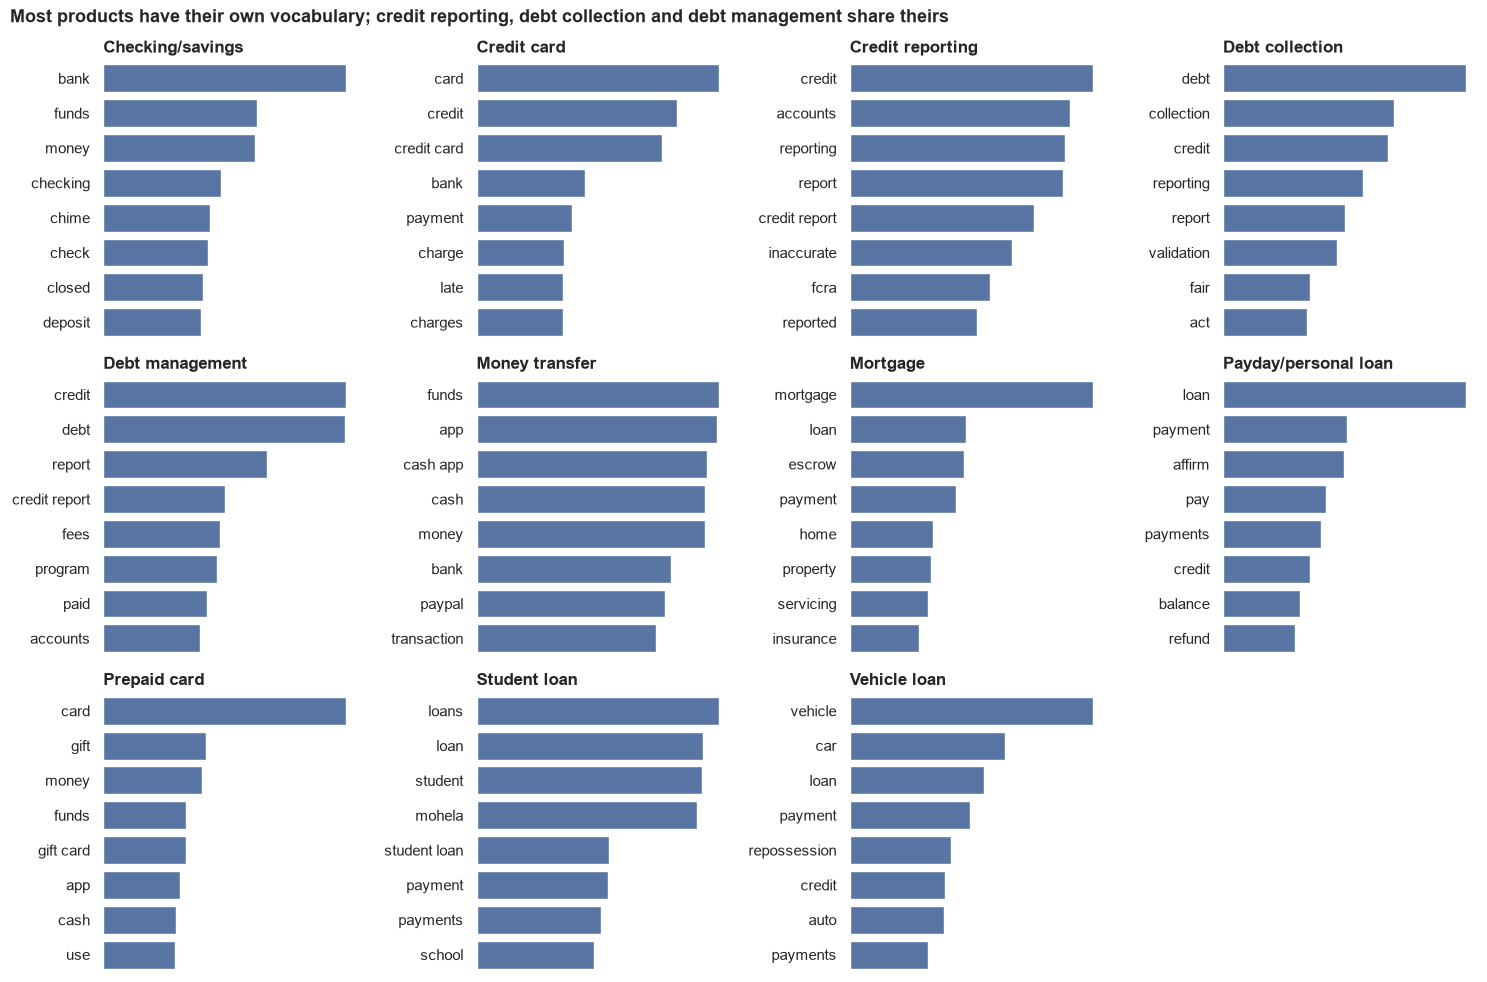

In [17]:
# Top 8 distinctive terms per product (highest average TF-IDF score)
distinct = distinctive_terms(text_df["clean"], text_df["product_short"], n=8)

# One small bar chart per product, arranged in a 3 x 4 grid
products = sorted(distinct["product"].unique())
fig, axes = plt.subplots(3, 4, figsize=(15, 10))
for ax, product in zip(axes.flat, products):
    terms = distinct[distinct["product"] == product]   # this product's 8 terms
    sns.barplot(data=terms, x="score", y="term", color=MAIN, ax=ax)
    ax.set(title=product, xlabel="", ylabel="", xticks=[])   # scores only compare words within a product, so no x-axis
    sns.despine(ax=ax, left=True, bottom=True)
axes.flat[-1].axis("off")    # 11 products in a 12-slot grid: hide the empty one

fig.suptitle("Most products have their own vocabulary; credit reporting, debt collection and debt management share theirs",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

- **Eight products have clear, product-specific vocabulary:** mortgage (*escrow, property, servicing*), student loan (*school, mohela*), vehicle loan (*repossession, auto*), checking/savings (*deposit, check*), prepaid card (*gift card*). These should be easy to classify.
- **Credit reporting, debt collection and debt management share their top words** (*credit*, *report*). Debt management complaints are often about credit repair companies promising to fix a credit report, so their language overlaps with credit reporting. These categories share similar vocabulary, so we will examine whether the classification models confuse them more frequently in Phase 3.
- Company names show up as distinctive terms (*chime, mohela, affirm, paypal*). This confirms the point from 2.2: part of the signal is *who* the complaint is about, not just *what* it is about.

### 2.4 Word clouds: overlapping vs. distinct vocabulary

Word size shows how distinctive a word is for that product (TF-IDF). The three overlapping products sit beside mortgage, which has its own vocabulary.

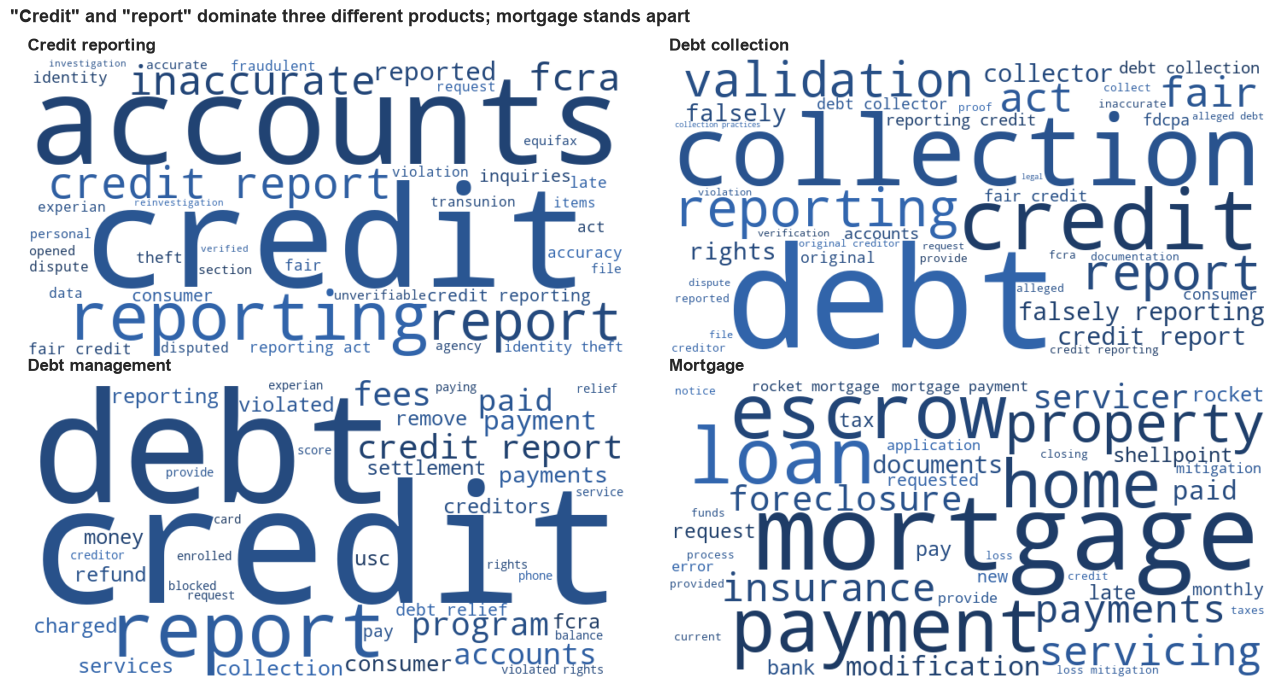

In [18]:
# Word clouds for the three overlapping products and one distinct product
cloud_products = ["Credit reporting", "Debt collection", "Debt management", "Mortgage"]
cloud_terms = distinctive_terms(text_df["clean"], text_df["product_short"], n=40)   # top 40 TF-IDF terms per product

def dark_blue(*args, **kwargs):
    # Colour every word in a readable dark blue (shades vary for texture)
    return f"hsl(215, 55%, {np.random.randint(25, 45)}%)"

# Draw one cloud per product in a 2 x 2 grid; word size = TF-IDF score
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, product in zip(axes.flat, cloud_products):
    weights = cloud_terms[cloud_terms["product"] == product].set_index("term")["score"].to_dict()   # {word: score}
    cloud = WordCloud(width=700, height=350, background_color="white", color_func=dark_blue,
                      prefer_horizontal=1.0, random_state=1).generate_from_frequencies(weights)
    ax.imshow(cloud, interpolation="bilinear")
    ax.set_title(product)
    ax.axis("off")   # hide the axes around the image

fig.suptitle('"Credit" and "report" dominate three different products; mortgage stands apart',
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

The first three clouds are dominated by the same words (*credit, report, reporting, debt*), while the mortgage cloud shares almost none of them. For the routing team this means a complaint that talks about a credit report could belong to any of three teams; the deciding clues are smaller words such as *validation* (debt collection) or *program, fees* (debt management).

### 2.5 Vocabulary Overlap Across Financial Products (Jaccard Similarity)

We use Jaccard similarity to measure how much vocabulary is shared between financial product categories.

Jaccard similarity compares the number of shared words with the total number of unique words across two sets.

A score of 0 indicates no shared words, while a score of 1 indicates identical word sets.

This analysis helps us identify product categories with similar vocabulary and explore which categories might be more difficult to distinguish during predictive modeling.

In [19]:
# Get the 50 most common meaningful words for each financial product
top_words_by_product = {}

for product, group in text_df.groupby("Product"):

    # Combine the cleaned narratives and remove stopwords
    words = " ".join(group["clean"]).split()
    words = [word for word in words if word not in STOPWORDS]

    # Select the 50 most frequent words for each product
    word_counts = Counter(words)
    top_words_by_product[product] = set(
        word for word, count in word_counts.most_common(50)
    )

# Calculate Jaccard similarity between each pair of products
products = list(top_words_by_product.keys())

jaccard_matrix = pd.DataFrame(
    index=products,
    columns=products,
    dtype=float
)

for product_a in products:
    for product_b in products:
        words_a = top_words_by_product[product_a]
        words_b = top_words_by_product[product_b]

        # Count shared words and total unique words
        shared_words = len(words_a.intersection(words_b))
        total_unique_words = len(words_a.union(words_b))

        # Calculate Jaccard similarity
        jaccard_matrix.loc[product_a, product_b] = (
            shared_words / total_unique_words if total_unique_words else 0
        )

# Display the similarity scores
display(jaccard_matrix.round(2))

,Checking or savings account,Credit card,Credit reporting or other personal consumer reports,Debt collection,Debt or credit management,"Money transfer, virtual currency, or money service",Mortgage,"Payday loan, title loan, personal loan, or advance loan",Prepaid card,Student loan,Vehicle loan or lease
Checking or savings account,1.00,0.37,0.16,0.16,0.25,0.54,0.20,0.27,0.47,0.16,0.20
Credit card,0.37,1.00,0.19,0.22,0.39,0.32,0.25,0.45,0.32,0.25,0.35
Credit reporting or other personal consumer reports,0.16,0.19,1.00,0.47,0.27,0.10,0.11,0.20,0.09,0.16,0.23
Debt collection,0.16,0.22,0.47,1.00,0.37,0.14,0.16,0.32,0.12,0.20,0.33
Debt or credit management,0.25,0.39,0.27,0.37,1.00,0.23,0.28,0.45,0.20,0.33,0.39
"Money transfer, virtual currency, or money service",0.54,0.32,0.10,0.14,0.23,1.00,0.19,0.27,0.54,0.18,0.19
Mortgage,0.20,0.25,0.11,0.16,0.28,0.19,1.00,0.32,0.18,0.28,0.35
"Payday loan, title loan, personal loan, or advance loan",0.27,0.45,0.20,0.32,0.45,0.27,0.32,1.00,0.25,0.32,0.54
Prepaid card,0.47,0.32,0.09,0.12,0.20,0.54,0.18,0.25,1.00,0.14,0.16
Student loan,0.16,0.25,0.16,0.20,0.33,0.18,0.28,0.32,0.14,1.00,0.28


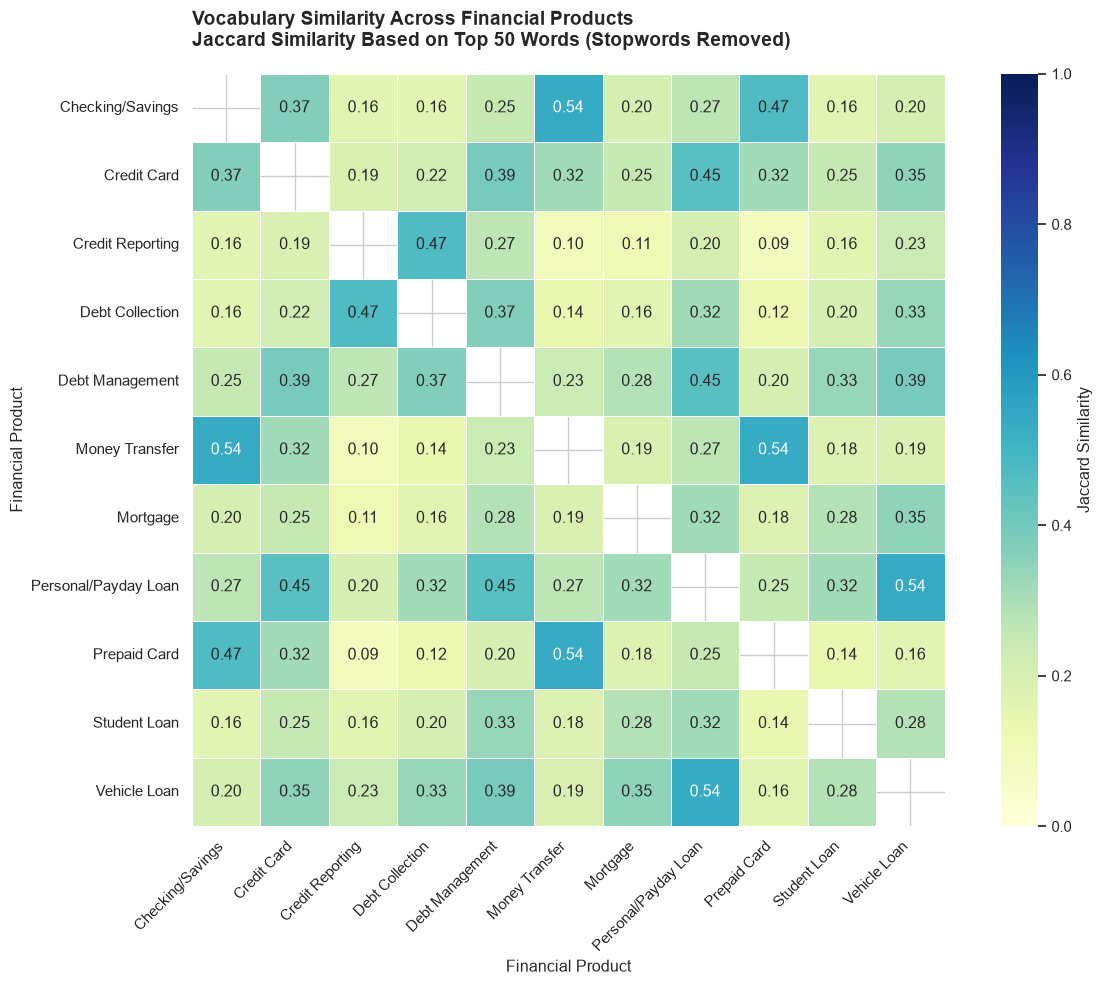

In [20]:
# Shorten product names to make the heatmap easier to read
short_names = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt Management",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Personal/Payday Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan"
}

# Apply shorter labels without changing the similarity scores
plot_matrix = jaccard_matrix.rename(
    index=short_names,
    columns=short_names
)

# Hide self-comparisons along the diagonal
mask = np.eye(len(plot_matrix), dtype=bool)

plt.figure(figsize=(13, 10))

sns.heatmap(
    plot_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    square=True,
    cbar_kws={"label": "Jaccard Similarity"}
)

plt.title(
    "Vocabulary Similarity Across Financial Products\n"
    "Jaccard Similarity Based on Top 50 Words (Stopwords Removed)",
    fontsize=14,
    fontweight="bold",
    pad=20
)

plt.xlabel("Financial Product")
plt.ylabel("Financial Product")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

### Interpretation: Vocabulary Similarity Across Financial Products

The Jaccard similarity analysis compares the 50 most frequent words in each financial product category after removing stopwords.

- **Highest similarity (0.54):** Checking/Savings and Money Transfer, Money Transfer and Prepaid Card, and Personal/Payday Loan and Vehicle Loan share the most vocabulary. This makes sense because these products involve related financial activities.

- **Lowest similarity (0.09):** Credit Reporting and Prepaid Card have the least vocabulary overlap, suggesting that consumers use different language when describing problems with these products.

- **Credit Reporting and Debt Collection (0.47):** These categories share several common terms, which may make them harder for classification models to distinguish.

Overall, the results show that some financial products have distinct vocabularies, while others share similar language. This overlap may help explain potential classification errors when we evaluate our models in Phase 3.

### 2.6 Do complaints name their own product?

If most complaints simply say "my mortgage" or "my student loan", classification is easy but partly trivial. The chart shows, for complaints of each product (rows), the share that mention the key words of each product (columns). Numbers on the outlined diagonal mean complaints name their own product; strong numbers off the diagonal mean they mention another product's words.

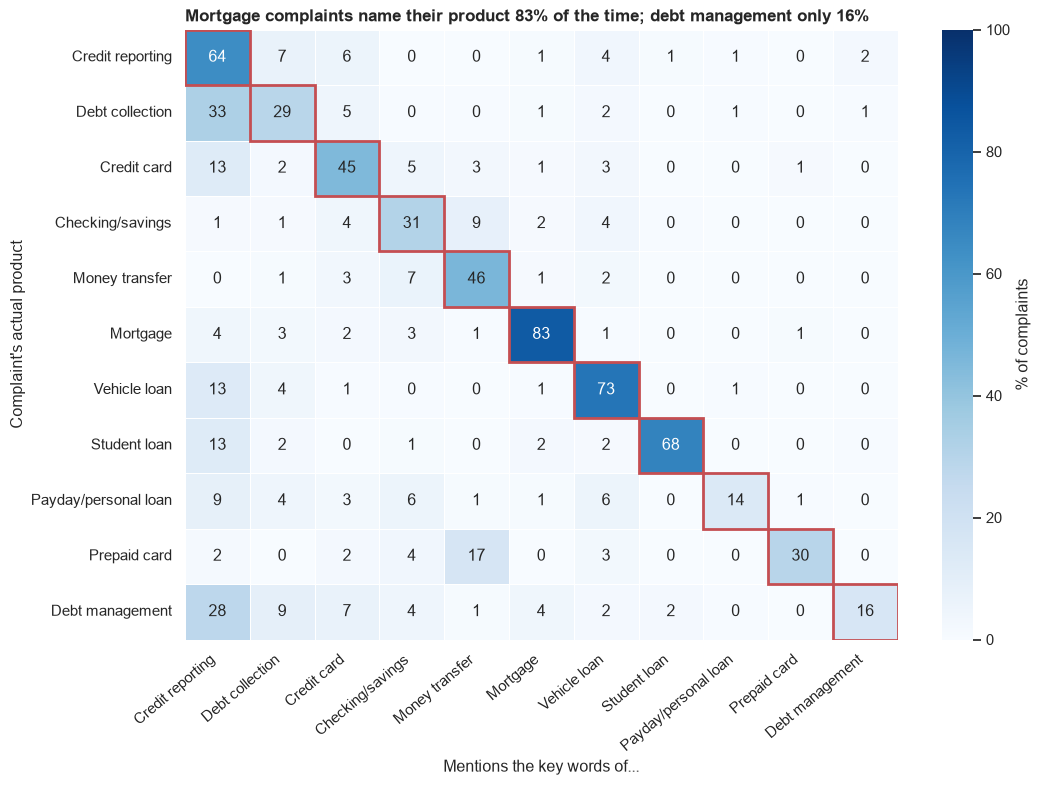

In [21]:
# % of complaints in each product (rows) that mention each product's key words (columns)
mentions = product_word_matrix(text_df)

# Heatmap: rows = actual product, columns = product whose key words are mentioned, cell = % of complaints
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(mentions, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "% of complaints"}, ax=ax)
ax.set(xlabel="Mentions the key words of...", ylabel="Complaint's actual product",
       title="Mortgage complaints name their product 83% of the time; debt management only 16%")

# Outline the diagonal: complaints mentioning their own product's words
for i in range(len(mentions)):
    ax.add_patch(plt.Rectangle((i, i), 1, 1, fill=False, edgecolor=ACCENT, linewidth=2))
plt.xticks(rotation=40, ha="right")   # tilt column names so they do not overlap
plt.tight_layout()
plt.show()

- **Some products almost always name themselves:** mortgage (83%), vehicle loan (73%), student loan (68%) and credit reporting (64%). For these, a model can score well just by spotting the product word, which is why Phase 3 will **re-test the model with these words masked** to see how much accuracy depends on them.
- **Others rarely do:** only 14% of payday/personal loan and 16% of debt management complaints use their own product's words. These classes depend on indirect clues and will likely be harder.
- **The key off-diagonal finding:** 33% of debt collection complaints and 28% of debt management complaints use credit-reporting words, as much as or more than their own. This matches 2.3 and 2.4: credit reporting, debt collection and debt management are the classes we expect the model to confuse, and the cases where the routing team would most benefit from a second look.

### 2.7 Sentiment Analysis Using VADER

We use VADER sentiment analysis to examine the emotional tone of consumer complaint narratives. VADER assigns sentiment scores based on the words and expressions in a text.

This analysis will help us understand the overall sentiment of complaints and compare sentiment across financial product categories.

In [22]:
# Baseline VADER score for every complaint
text_df["sentiment_raw"] = sentiment_scores(text_df[TEXT_COL])            # compound score from -1 to +1
text_df["label_raw"] = sentiment_label(text_df["sentiment_raw"])          # Negative < -0.05 <= Neutral <= 0.05 < Positive

# Share of complaints in each sentiment label
print("Share of complaints by sentiment label (baseline VADER):")
print((text_df["label_raw"].value_counts(normalize=True) * 100).round(1).to_string())

Share of complaints by sentiment label (baseline VADER):
label_raw
Negative    60.1
Positive    36.0
Neutral      3.9


- VADER calls about **36% of complaints positive**, even though every narrative here is a complaint. To find out why, we add up which positive dictionary words contribute most across all complaints.

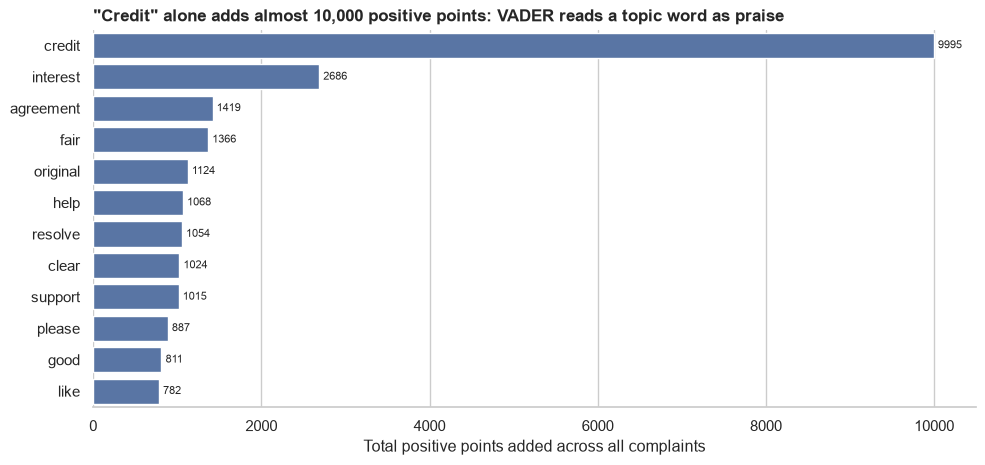

In [23]:
# Positive dictionary words that add the most to VADER scores
contributions = positive_word_contributions(text_df["clean"], n=12)   # top 12 words by total positive score added

# Horizontal bar chart of those words
fig, ax = plt.subplots(figsize=(10, 4.8))
sns.barplot(data=contributions, x="positive_points", y="word", color=MAIN, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3, fontsize=8)
ax.set(xlabel="Total positive points added across all complaints", ylabel="",
       title='"Credit" alone adds almost 10,000 positive points: VADER reads a topic word as praise')
sns.despine(left=True)
plt.tight_layout()
plt.show()

- VADER was built for social media, where *credit* means praise ("give credit") and *interest* means curiosity. In financial complaints these are **topic words**: *credit report*, *interest rate*, the **Fair** Credit Reporting Act, a loan **agreement**, even **Wells** Fargo. They inflate scores, most of all for credit-related products.

**Domain-adjusted sentiment analysis:** We make selected financial terms neutral in VADER's dictionary (`FINANCE_WORDS` in `src/text_analysis.py`) and calculate sentiment scores again. This is an experimental adjustment to reduce the influence of financial terminology, not a guaranteed improvement in sentiment accuracy.


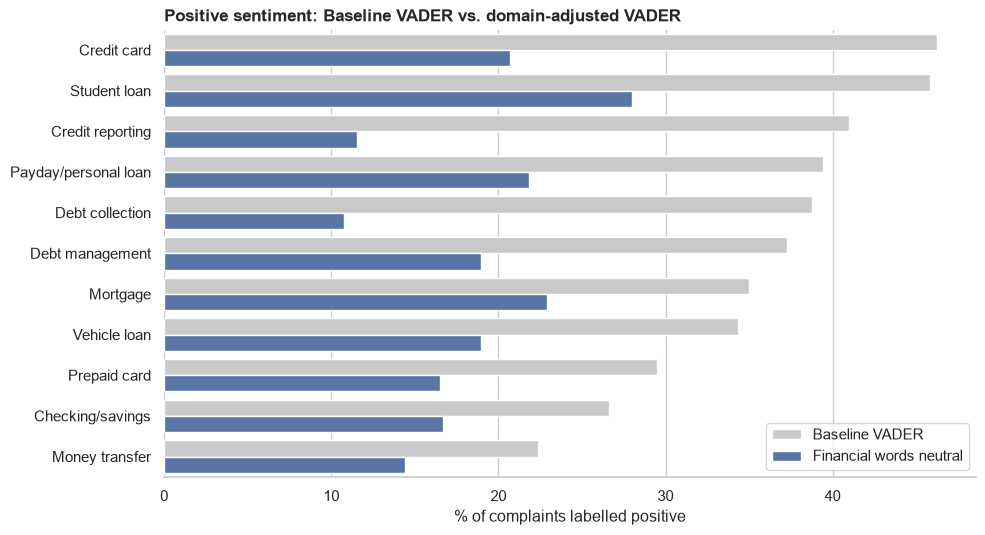

Overall share labelled positive: baseline 36%, domain-adjusted 18%


In [24]:
# Re-score with financial topic words made neutral
text_df["sentiment"] = sentiment_scores(text_df[TEXT_COL], neutral_words=FINANCE_WORDS)   # FINANCE_WORDS scored as 0
text_df["label"] = sentiment_label(text_df["sentiment"])

# Compare positive sentiment percentages before and after domain adjustment
positive_share = pd.DataFrame({
    "Baseline VADER": text_df["label_raw"].eq("Positive").groupby(text_df["product_short"]).mean() * 100,
    "Financial words neutral": text_df["label"].eq("Positive").groupby(text_df["product_short"]).mean() * 100,
}).sort_values("Baseline VADER", ascending=False)

# Reshape to long format (one row per product and version) so seaborn can draw paired bars
plot_data = positive_share.reset_index().melt(id_vars="product_short", var_name="version",
                                              value_name="pct_positive")
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.barplot(data=plot_data, x="pct_positive", y="product_short", hue="version",
            palette=["#c9c9c9", MAIN], ax=ax)
ax.set(xlabel="% of complaints labelled positive", ylabel="",
       title="Positive sentiment: Baseline VADER vs. domain-adjusted VADER")
ax.legend(title="", loc="lower right")
sns.despine(left=True)
plt.tight_layout()
plt.show()

# Compare the overall share of positive sentiment before and after domain adjustment
print("Overall share labelled positive:",
      f"baseline {text_df['label_raw'].eq('Positive').mean():.0%},",
      f"domain-adjusted {text_df['label'].eq('Positive').mean():.0%}")


- After making selected financial terms neutral, VADER classified approximately **77% of complaints as negative**, compared with the baseline results.
- The percentage classified as positive decreased, especially for credit reporting, debt collection, and credit card complaints.
- About **18% of complaints still received positive sentiment labels**. Words such as *help*, *resolve*, *support*, and *please* may contribute to these scores even when consumers are describing problems.
- **Takeaway:** Domain-specific terminology can influence sentiment scores. However, this adjustment is experimental, and we would need manually labeled sentiment data to determine whether it improves accuracy.


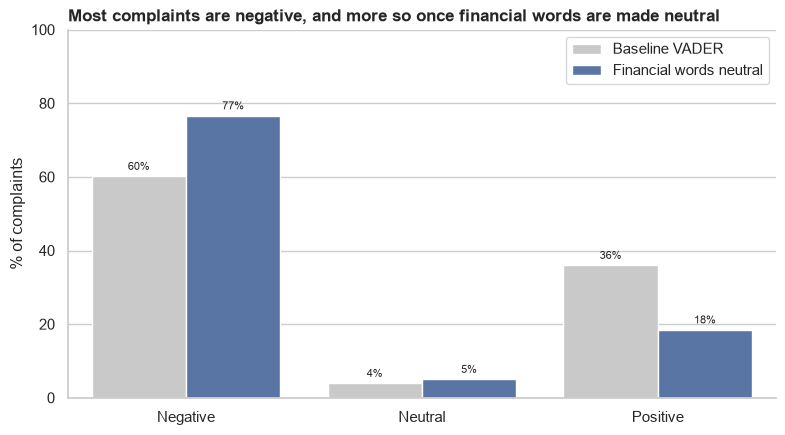

          Baseline VADER  Financial words neutral
Negative            60.1                     76.6
Neutral              3.9                      5.0
Positive            36.0                     18.4


In [25]:
# Share of complaints by sentiment label: baseline VADER vs. financial words neutral
order = ["Negative", "Neutral", "Positive"]   # fixed order for the x-axis
label_share = pd.DataFrame({
    "Baseline VADER": text_df["label_raw"].value_counts(normalize=True) * 100,
    "Financial words neutral": text_df["label"].value_counts(normalize=True) * 100,
}).reindex(order)

# Reshape to long format (one row per label and version) for paired bars
plot_data = label_share.reset_index(names="sentiment").melt(id_vars="sentiment", var_name="version",
                                                            value_name="pct")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=plot_data, x="sentiment", y="pct", hue="version", order=order,
            palette=["#c9c9c9", MAIN], ax=ax)
for container in ax.containers:   # write the % above every bar
    ax.bar_label(container, fmt="%.0f%%", padding=3, fontsize=8)
ax.set(xlabel="", ylabel="% of complaints", ylim=(0, 100),
       title="Most complaints are negative, and more so once financial words are made neutral")
ax.legend(title="", loc="upper right")
sns.despine()
plt.tight_layout()
plt.show()

print(label_share.round(1).to_string())

- With baseline VADER, **60% of complaints are negative, 36% positive and 4% neutral**. Since every narrative is a complaint, a positive share this high is a warning sign.
- After financial topic words (*credit*, *interest*, *fair*, *agreement*) are made neutral, **77% of complaints are negative and 18% positive**. Almost all of the change moves from positive to negative; the neutral share stays small (4% to 5%).

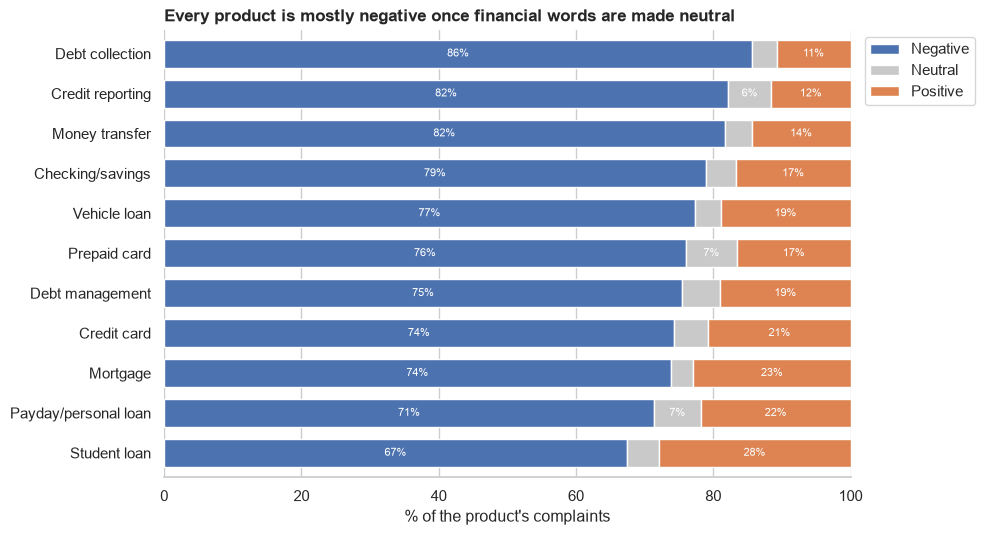

label                 Negative  Neutral  Positive
product_short                                    
Debt collection           85.6      3.6      10.8
Credit reporting          82.2      6.3      11.6
Money transfer            81.6      4.0      14.4
Checking/savings          78.9      4.4      16.7
Vehicle loan              77.3      3.7      18.9
Prepaid card              76.0      7.5      16.5
Debt management           75.4      5.6      19.0
Credit card               74.2      5.1      20.7
Mortgage                  73.8      3.3      22.9
Payday/personal loan      71.4      6.8      21.8
Student loan              67.4      4.6      28.0


In [26]:
# Negative / neutral / positive mix for each product (financial words neutral)
# % of each product's complaints in each label (each row adds up to 100)
sentiment_by_product = (pd.crosstab(text_df["product_short"], text_df["label"], normalize="index") * 100)
sentiment_by_product = sentiment_by_product[["Negative", "Neutral", "Positive"]].sort_values("Negative")

# One stacked bar per product: negative + neutral + positive = 100%
ax = sentiment_by_product.plot(kind="barh", stacked=True, figsize=(10, 5.5), width=0.7,
                               color=["#4c72b0", "#c9c9c9", "#dd8452"])
# Label each segment with its %, skipping segments under 6% that are too narrow to read
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.0f}%" if v >= 6 else "" for v in container.datavalues],
                 label_type="center", fontsize=8, color="white")
ax.set(xlim=(0, 100), xlabel="% of the product's complaints", ylabel="",
       title="Every product is mostly negative once financial words are made neutral")
ax.legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine(left=True)
plt.tight_layout()
plt.show()

print(sentiment_by_product.round(1).sort_values("Negative", ascending=False).to_string())

- **Every product is mostly negative** once financial words are made neutral. Debt collection has the highest negative share (86%) and student loan the lowest (67%, with the highest positive share at 28%).
- Debt collection and credit reporting have some of the highest negative sentiment percentages after the domain adjustment. Their positive sentiment percentages decreased substantially, suggesting that financial terminology influenced the original VADER scores. However, we cannot confirm that the original positive labels were incorrect without manually reviewing and labeling the complaints.

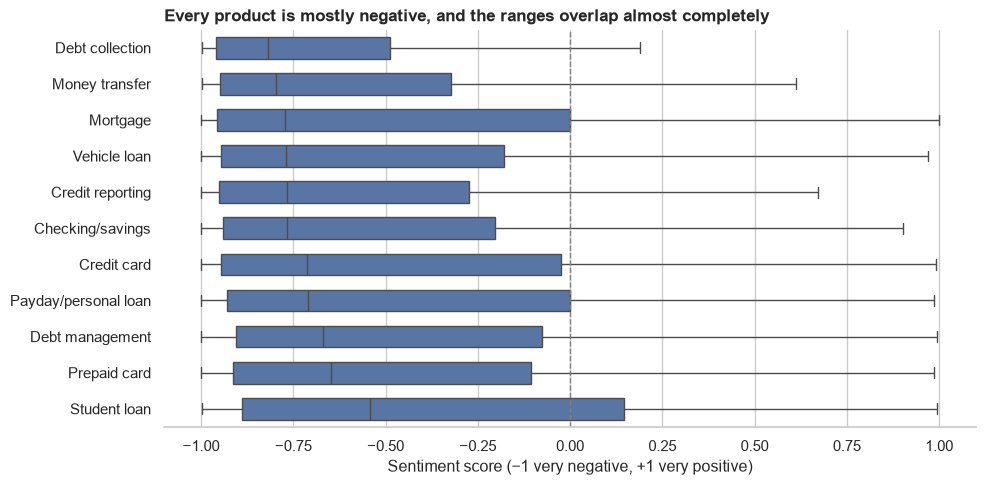

                              median  count
Company response to consumer               
Closed with explanation        -0.74   3971
Other                          -0.36    201
Relief given                   -0.75    723


In [27]:
# Does sentiment differ by product? (adjusted scores)
# Products ordered from most negative to least negative median score
order_by_sentiment = text_df.groupby("product_short")["sentiment"].median().sort_values().index

# Box = middle half of scores, line = median, whiskers = typical range (outliers hidden)
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=text_df, x="sentiment", y="product_short", order=order_by_sentiment,
            color=MAIN, showfliers=False, width=0.6, ax=ax)
ax.axvline(0, color="grey", linewidth=1, linestyle="--")   # neutral line
ax.set(xlabel="Sentiment score (−1 very negative, +1 very positive)", ylabel="",
       title="Every product is mostly negative, and the ranges overlap almost completely")
sns.despine(left=True)
plt.tight_layout()
plt.show()

# Does sentiment differ by how the company responded?
# Group company responses into three outcomes, then compare median sentiment and counts
outcome = text_df["Company response to consumer"].map(
    lambda r: "Relief given" if "relief" in r else ("Closed with explanation" if "explanation" in r else "Other"))
print(text_df.groupby(outcome)["sentiment"].agg(["median", "count"]).round(2))

- Median sentiment ranges only from about −0.8 (debt collection, money transfer) to −0.5 (student loan), and the boxes overlap heavily. **Sentiment will not help the model tell products apart**, so we will not use it as a classification feature in Phase 3.
- Sentiment is also the same whether the company gave relief or just closed with an explanation (both about −0.75). So for our stretch question, *how angry* a consumer sounds does not predict *whether they get relief*.
- Where sentiment could still help is in **prioritising** within a team's queue (the most negative complaints first). If we need a reliable severity or urgency score, Claude can judge it from context, which a word list cannot. We will test that in our Phase 3 plan.

### 2.8 Summary: what Phase 2 means for Phase 3

| Finding | Evidence | Phase 3 action |
|---|---|---|
| Balanced sample (454–455 per product); real complaints are 91% credit reporting | 1.3 | Report accuracy and macro F1; note that a balanced model over-predicts small products on real traffic |
| 105 exact copies of 44 template letters | 1.6 | Remove copies before the train/test split (4,895 narratives) |
| Most products have their own vocabulary | 2.3, 2.4 | TF-IDF features with logistic regression as the baseline |
| Credit reporting, debt collection and debt management share vocabulary | 2.3–2.5 | Per-class precision and recall, and a confusion matrix |
| Many complaints name their own product (mortgage 83%) | 2.6 | Re-train with product words masked and compare macro F1 |
| Company names are among the most common and distinctive terms | 2.2, 2.3 | Inspect top features; test a version with company names removed |
| Sentiment is mostly negative for every product and overlaps across products | 2.7 | Do not use sentiment as a classification feature |

## 3. Phase III — Predictive Modeling

### 3.1 Data Preparation and Train/Test Split

Building on our exploratory data analysis and text preprocessing, we use the unique complaint narratives prepared in Section 2.1.

Following our Phase I proposal, we create a reproducible 70/30 stratified train/test split. Stratification preserves the distribution of the 11 financial product categories across both datasets.

The training data will be used to develop our classification models and generate category descriptions for the embedding-based approach. The test data will be held out for final model evaluation.

In [28]:
# Use the deduplicated complaints from Section 2.1
model_df = text_df.copy()

# Define the complaint narratives and product categories
X = model_df[TEXT_COL]
y = model_df["Product"]

# Create a reproducible 70/30 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

print(f"Total complaints: {len(model_df):,}")
print(f"Training complaints: {len(X_train):,}")
print(f"Testing complaints: {len(X_test):,}")
print(f"Product categories: {y.nunique()}")

# Compare category distributions across the datasets
split_distribution = pd.DataFrame({
    "Overall (%)": y.value_counts(normalize=True) * 100,
    "Training (%)": y_train.value_counts(normalize=True) * 100,
    "Testing (%)": y_test.value_counts(normalize=True) * 100
}).round(2)

display(split_distribution)

Total complaints: 4,895
Training complaints: 3,426
Testing complaints: 1,469
Product categories: 11


,Overall (%),Training (%),Testing (%)
Product,,,
Checking or savings account,9.30,9.28,9.33
Credit card,9.27,9.28,9.26
Credit reporting or other personal consumer reports,8.13,8.14,8.10
Debt collection,8.54,8.52,8.58
Debt or credit management,9.15,9.14,9.19
"Money transfer, virtual currency, or money service",9.23,9.22,9.26
Mortgage,9.27,9.28,9.26
"Payday loan, title loan, personal loan, or advance loan",9.27,9.28,9.26
Prepaid card,9.27,9.28,9.26


### Interpretation: Train/Test Split

After removing duplicate narratives, 4,895 complaints remained. Following our Phase I proposal, we allocated 3,426 complaints (70%) to training and 1,469 (30%) to testing.

The stratified split preserved the distribution of all 11 financial product categories, with only minor differences between the training and testing proportions.

We use the same split across all classification approaches to ensure a fair comparison. The test set will remain held out during model development.

### 3.2 TF-IDF Feature Extraction

We use Term Frequency–Inverse Document Frequency (TF-IDF) to convert complaint narratives into numerical features for classification.

Following our Phase I proposal, we include both unigrams (individual words) and bigrams (two-word phrases) to capture financial terminology and context.

The vectorizer is fitted only on the training data to prevent information leakage. We then apply the fitted vectorizer to the test data without learning any new vocabulary.

The resulting TF-IDF features will be used to train and compare Multinomial Naïve Bayes, Logistic Regression, and Linear SVM.

In [29]:
# Create TF-IDF features using unigrams and bigrams
tfidf = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
)

# Learn vocabulary from training complaints only
X_train_tfidf = tfidf.fit_transform(X_train)

# Apply the same vocabulary to test complaints
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)
print("Number of TF-IDF features:", len(tfidf.get_feature_names_out()))

Training TF-IDF shape: (3426, 25231)
Testing TF-IDF shape: (1469, 25231)
Number of TF-IDF features: 25231


### Interpretation: TF-IDF Features

The TF-IDF vectorizer produced 25,231 features from the training complaints, including individual words and two-word phrases.

The training matrix contains 3,426 complaints, while the testing matrix contains 1,469 complaints. Both matrices have the same number of features because the test data was transformed using the vocabulary learned from the training set.

These features provide the numerical representation needed to train our classification models. Fitting the vectorizer only on the training data also prevents vocabulary-related information leakage from the test set.

### 3.3 Multinomial Naïve Bayes

Multinomial Naïve Bayes is our first baseline classification model. It is commonly used for text classification because it is computationally efficient and works well with high-dimensional text features.

We train the model using the TF-IDF features extracted from consumer complaint narratives to predict the financial product category.

We evaluate the model using 5-fold stratified cross-validation on the training data. This allows us to assess its performance without using the held-out test set.

We report cross-validation accuracy and macro F1-score. Macro F1 gives equal importance to all 11 financial product categories.

In [30]:
# Use the same cross-validation settings for all models
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Combine TF-IDF and Naïve Bayes in one pipeline
nb_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=3,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("model", MultinomialNB(alpha=1.0))
])

# Evaluate using the original training narratives
nb_cv = cross_validate(
    nb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
    n_jobs=-1
)

print(f"Mean CV Accuracy: {nb_cv['test_accuracy'].mean():.4f}")
print(f"Mean CV Macro F1: {nb_cv['test_f1_macro'].mean():.4f}")
print(f"Accuracy SD: {nb_cv['test_accuracy'].std():.4f}")
print(f"Macro F1 SD: {nb_cv['test_f1_macro'].std():.4f}")

# Fit the complete pipeline on all training complaints
nb_pipeline.fit(X_train, y_train)

Mean CV Accuracy: 0.6699
Mean CV Macro F1: 0.6622
Accuracy SD: 0.0187
Macro F1 SD: 0.0226


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U55](11,)","['Checking or savings account','Credit card', 'Credit reporting or other personal consumer reports',...,'Prepaid card', 'Student loan','Vehicle loan or lease']"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_df max_df: float or int, default=1.0When building the vocabulary ignore terms that have a documentfrequency strictly higher than the given threshold (corpus-specificstop words).If float in range [0.0, 1.0], the parameter represents a proportion ofdocuments, integer absolute counts.This parameter is ignored if vocabulary is not None.",0.95
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",3
,"su

### Interpretation: Multinomial Naïve Bayes Results

Multinomial Naïve Bayes achieved a mean cross-validation accuracy of 66.99% and a macro F1-score of 66.22% across five folds.

The model correctly classified approximately two-thirds of the validation complaints across the 11 financial product categories. The relatively small standard deviations (0.0187 for accuracy and 0.0226 for macro F1) indicate reasonably consistent performance across folds.

Using a pipeline ensures that TF-IDF features are learned separately within each cross-validation fold, preventing information leakage during validation.

These results establish our baseline for comparing Logistic Regression, Linear SVM, and embedding-based classification.

### 3.4 Logistic Regression

Logistic Regression was implemented as the second supervised learning approach to predict financial product categories from consumer complaint narratives. The model uses TF-IDF representations of unigrams and bigrams to identify patterns in complaint language associated with each of the 11 product categories.

To ensure consistency across models, we applied the same text preprocessing settings and five-fold stratified cross-validation procedure used for Multinomial Naïve Bayes. TF-IDF vectorization and classification were combined in a pipeline to prevent information leakage during cross-validation.

Model performance was assessed using mean cross-validation accuracy and macro F1-score, with standard deviations reported to evaluate consistency across folds. The results were compared with the Naïve Bayes baseline to determine whether Logistic Regression provides improved classification performance.

In [31]:
# Combine TF-IDF and Logistic Regression in one pipeline
lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=3,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

# Evaluate using five-fold stratified cross-validation
lr_cv = cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
    n_jobs=1
)

print(f"Mean CV Accuracy: {lr_cv['test_accuracy'].mean():.4f}")
print(f"Mean CV Macro F1: {lr_cv['test_f1_macro'].mean():.4f}")
print(f"Accuracy SD: {lr_cv['test_accuracy'].std():.4f}")
print(f"Macro F1 SD: {lr_cv['test_f1_macro'].std():.4f}")

# Fit the final pipeline on all training complaints
lr_pipeline.fit(X_train, y_train)

Mean CV Accuracy: 0.7131
Mean CV Macro F1: 0.7127
Accuracy SD: 0.0123
Macro F1 SD: 0.0135


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](11,)","['Checking or savings account','Credit card', 'Credit reporting or other personal consumer reports',...,'Prepaid card', 'Student loan','Vehicle loan or lease']"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_df max_df: float or int, default=1.0When building the vocabulary ignore terms that have a documentfrequency strictly higher than the given threshold (corpus-specificstop words).If float in range [0.0, 1.0], the parameter represents a proportion ofdocuments, integer absolute counts.This parameter is ignored if vocabulary is not None.",0.95
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",3
,"

### Interpretation: Logistic Regression Results

Logistic Regression achieved a mean cross-validation accuracy of 71.31% and a macro F1-score of 71.27%, outperforming Multinomial Naïve Bayes on both metrics.

Compared with Naïve Bayes, Logistic Regression improved accuracy by 4.32 percentage points and macro F1 by 5.05 percentage points. The smaller standard deviations (0.0123 for accuracy and 0.0135 for macro F1) also indicate more consistent performance across validation folds.

These findings suggest that Logistic Regression is better suited to distinguishing financial product categories from complaint narratives within our current modeling framework. Its higher macro F1-score indicates improved classification performance across the 11 categories.

Logistic Regression is currently our strongest-performing model based on cross-validation results. However, Linear SVM and the embedding-based approach will also be evaluated before selecting the final model.

### 3.5 Linear Support Vector Machine (Linear SVM)

Linear Support Vector Machine (Linear SVM) was implemented as the third supervised learning approach to classify consumer complaint narratives into the 11 financial product categories. The model identifies decision boundaries that separate product categories based on their TF-IDF representations.

To maintain consistency across the supervised learning models, Linear SVM was evaluated using the same unigram and bigram TF-IDF settings and five-fold stratified cross-validation procedure. Text vectorization and classification were combined in a pipeline to prevent information leakage during validation.

Model performance was assessed using mean cross-validation accuracy and macro F1-score, with standard deviations reported to evaluate consistency across folds. The results were compared with Multinomial Naïve Bayes and Logistic Regression to identify the strongest-performing traditional classification approach.

In [32]:
# Combine TF-IDF and Linear SVM in one pipeline
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=3,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("model", LinearSVC(C=1.0, max_iter=5000, random_state=42))
])

# Evaluate using five-fold stratified cross-validation
svm_cv = cross_validate(
    svm_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={"accuracy": "accuracy", "f1_macro": "f1_macro"},
    n_jobs=1
)

print(f"Mean CV Accuracy: {svm_cv['test_accuracy'].mean():.4f}")
print(f"Mean CV Macro F1: {svm_cv['test_f1_macro'].mean():.4f}")
print(f"Accuracy SD: {svm_cv['test_accuracy'].std():.4f}")
print(f"Macro F1 SD: {svm_cv['test_f1_macro'].std():.4f}")

# Fit the complete pipeline on all training complaints
svm_pipeline.fit(X_train, y_train)

Mean CV Accuracy: 0.7262
Mean CV Macro F1: 0.7233
Accuracy SD: 0.0161
Macro F1 SD: 0.0176


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](11,)","['Checking or savings account','Credit card', 'Credit reporting or other personal consumer reports',...,'Prepaid card', 'Student loan','Vehicle loan or lease']"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_df max_df: float or int, default=1.0When building the vocabulary ignore terms that have a documentfrequency strictly higher than the given threshold (corpus-specificstop words).If float in range [0.0, 1.0], the parameter represents a proportion ofdocuments, integer absolute counts.This parameter is ignored if vocabulary is not None.",0.95
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",3
,"

### Interpretation: Linear SVM Results

Linear SVM achieved a mean cross-validation accuracy of 72.62% and a macro F1-score of 72.33%, outperforming both Multinomial Naïve Bayes and Logistic Regression.

Compared with Logistic Regression, Linear SVM improved accuracy by 1.31 percentage points and macro F1 by 1.06 percentage points. The standard deviations of 0.0161 for accuracy and 0.0176 for macro F1 indicate reasonably consistent performance across the five validation folds, although Logistic Regression demonstrated slightly lower variability.

These results suggest that Linear SVM is the strongest traditional classification model evaluated in this study. Its performance indicates that TF-IDF representations combined with linear decision boundaries are effective for distinguishing financial product categories from consumer complaint narratives.

However, the performance differences are based on cross-validation estimates. Final conclusions will consider held-out test performance and comparisons with the embedding-based classification approach.

### Interpretation: Cross-Validation Comparison

Across five stratified training folds, **Linear SVM** achieved the highest mean macro F1 (**0.7233**), followed by **Logistic Regression (0.7127)** and **Naïve Bayes (0.6622)**. Mean accuracy followed the same order (**0.7262**, **0.7131**, and **0.6699**, respectively). The SVM–Logistic Regression difference is modest, so both should be retained for held-out testing rather than declaring a definitive winner from cross-validation alone. The chart below summarizes these training-only estimates; it should not be confused with the final test comparison.

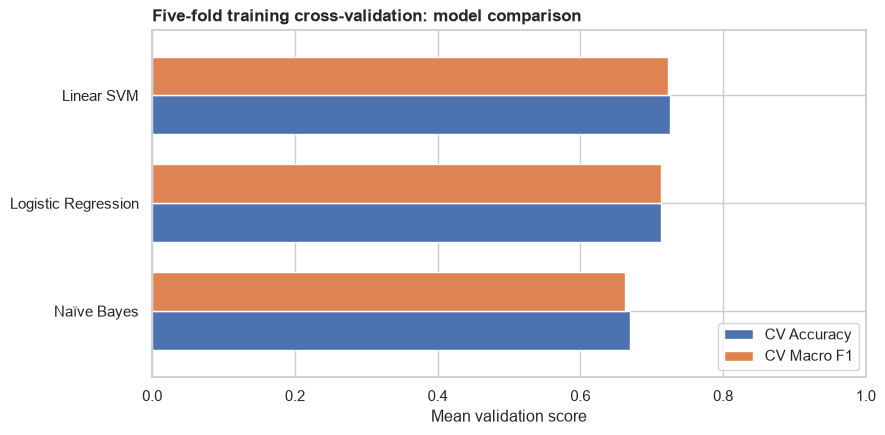

In [33]:
# Compare training-only cross-validation scores for the three traditional classifiers.
# This chart uses the recorded cross-validation arrays, not held-out test predictions.
cv_summary = pd.DataFrame({
    "Model": ["Naïve Bayes", "Logistic Regression", "Linear SVM"],
    "CV Accuracy": [nb_cv["test_accuracy"].mean(), lr_cv["test_accuracy"].mean(), svm_cv["test_accuracy"].mean()],
    "CV Macro F1": [nb_cv["test_f1_macro"].mean(), lr_cv["test_f1_macro"].mean(), svm_cv["test_f1_macro"].mean()]
}).set_index("Model")

ax = cv_summary.sort_values("CV Macro F1").plot(kind="barh", figsize=(9, 4.5), width=0.72)
ax.set(title="Five-fold training cross-validation: model comparison", xlabel="Mean validation score", ylabel="")
ax.set_xlim(0, 1)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_cv_comparison.png", dpi=180, bbox_inches="tight")
plt.show()


### 3.6 Claude-Generated Product Descriptions 

Claude generates one description for each of the 11 **product category labels only**. No consumer narratives, names, or account information are sent to Claude. This is a zero-shot, category-definition approach; it is **not** Claude learning from 110 example complaints. Descriptions are cached to avoid repeated API charges. A configured `ANTHROPIC_API_KEY_PROJECT` is required for the first generation run.

In [34]:
# Use category labels only; do not sample or transmit consumer complaints to Claude.
all_products = sorted(y_train.unique())
print("Product categories:", len(all_products))
display(pd.DataFrame({"Product": all_products}))

Product categories: 11


,Product
0,Checking or savings account
1,Credit card
2,Credit reporting or other personal consumer reports
3,Debt collection
4,Debt or credit management
5,"Money transfer, virtual currency, or money service"
6,Mortgage
7,"Payday loan, title loan, personal loan, or advance loan"
8,Prepaid card
9,Student loan


#### Claude prompt design

For privacy, Claude receives only a category name and instructions to describe its scope and distinguishing terminology. This avoids exposing complaint narratives to an external service. It is a different experiment from generating descriptions based on sampled complaints.

In [35]:
# No narrative sanitization is required: no complaint text is included in Claude requests.
claude_examples = {}
print("Consumer narratives sent to Claude: 0")

Consumer narratives sent to Claude: 0


In [36]:
def build_category_prompt(product):
    return f"""You are writing a reference definition for a financial consumer complaint classifier.
Category label: {product}
Describe the financial product/service, typical complaint issues, distinguishing terms, and
how it differs from related financial product categories. Use general domain knowledge only.
Do not invent case-specific details or refer to any individual consumer.
Write one concise paragraph of approximately 100–150 words. Return only the description."""

print("Prompt preview (category label only):")
print(build_category_prompt(all_products[0]))

Prompt preview (category label only):
You are writing a reference definition for a financial consumer complaint classifier.
Category label: Checking or savings account
Describe the financial product/service, typical complaint issues, distinguishing terms, and
how it differs from related financial product categories. Use general domain knowledge only.
Do not invent case-specific details or refer to any individual consumer.
Write one concise paragraph of approximately 100–150 words. Return only the description.


In [37]:
# Verify that prompts contain category labels, not consumer narratives.
review_df = pd.DataFrame({"Product": all_products, "Prompt": [build_category_prompt(p) for p in all_products]})
print("Prompts to generate:", len(review_df))
display(review_df[["Product"]])

Prompts to generate: 11


,Product
0,Checking or savings account
1,Credit card
2,Credit reporting or other personal consumer reports
3,Debt collection
4,Debt or credit management
5,"Money transfer, virtual currency, or money service"
6,Mortgage
7,"Payday loan, title loan, personal loan, or advance loan"
8,Prepaid card
9,Student loan


In [38]:
# Display a few category prompts without displaying sensitive complaint narratives.
with pd.option_context("display.max_colwidth", 200):
    display(review_df.head(3))
print("Consumer complaint narratives sent to Claude: 0")

,Product,Prompt
0,Checking or savings account,"You are writing a reference definition for a financial consumer complaint classifier.\nCategory label: Checking or savings account\nDescribe the financial product/service, typical complaint issues..."
1,Credit card,"You are writing a reference definition for a financial consumer complaint classifier.\nCategory label: Credit card\nDescribe the financial product/service, typical complaint issues, distinguishing..."
2,Credit reporting or other personal consumer reports,"You are writing a reference definition for a financial consumer complaint classifier.\nCategory label: Credit reporting or other personal consumer reports\nDescribe the financial product/service, ..."


Consumer complaint narratives sent to Claude: 0


In [39]:
# Load the project API key from .env
env_path = PROJECT_ROOT / ".env"
load_dotenv(env_path, override=True)

# Access the project-specific Claude API key
api_key = os.getenv("ANTHROPIC_API_KEY_PROJECT")

print("Environment file found:", env_path.exists())
print("Claude project API key available:", bool(api_key))
print("Categories ready:", len(claude_examples))
print("Total examples:", sum(len(v) for v in claude_examples.values()))

Environment file found: True
Claude project API key available: True
Categories ready: 0
Total examples: 0


In [40]:
# Initialize Claude only when credentials are present.
client = anthropic.Anthropic(api_key=api_key) if api_key else None
print("Claude client ready:", client is not None)

Claude client ready: True


#### 3.6.1 Automated generation and privacy controls

Generation is enabled by default and uses **only the 11 product labels**. It does not transmit any of the 110 sampled narratives or held-out test complaints to Claude. The JSON cache prevents repeated generation for categories already completed. API calls incur provider charges; if the API key is missing or the request fails, the notebook explains the problem instead of reporting fabricated model results.

In [41]:
# Fully automatic, label-only generation; no manual privacy approval needed.
RUN_CLAUDE_GENERATION = True
CLAUDE_MODEL = "claude-haiku-4-5-20251001"
DESCRIPTIONS_PATH = OUTPUT_DIR / "claude_label_only_descriptions.json"
category_descriptions = json.loads(DESCRIPTIONS_PATH.read_text(encoding="utf-8")) if DESCRIPTIONS_PATH.exists() else {}
category_descriptions = {k: v for k, v in category_descriptions.items() if k in all_products and isinstance(v, str) and v.strip()}
pending_categories = [p for p in all_products if p not in category_descriptions]
print("Cached category descriptions:", len(category_descriptions))
print("Descriptions awaiting generation:", len(pending_categories))

Cached category descriptions: 11
Descriptions awaiting generation: 0


In [42]:
# Generate category definitions from labels only; save each successful API response.
if pending_categories and RUN_CLAUDE_GENERATION:
    if client is None:
        raise RuntimeError("Set ANTHROPIC_API_KEY_PROJECT in the repository .env to generate Claude descriptions.")

    for product in pending_categories:
        response = client.messages.create(
            model=CLAUDE_MODEL,
            max_tokens=350,
            messages=[{"role": "user", "content": build_category_prompt(product)}]
        )

        description = " ".join(block.text for block in response.content if block.type == "text").strip()

        if not description:
            raise RuntimeError(f"Claude returned an empty description for {product}.")

        category_descriptions[product] = description
        DESCRIPTIONS_PATH.write_text(
            json.dumps(category_descriptions, indent=2, ensure_ascii=False),
            encoding="utf-8"
        )

        print(f"Saved: {product} ({len(description.split())} words)")

print(f"Available descriptions: {len(category_descriptions)}/{len(all_products)}")

Available descriptions: 11/11


In [43]:
# Quality assurance: show generated descriptions (not the source narratives).
# Review factual accuracy, product distinctions and any unexpected personal details.
if category_descriptions:
    descriptions_review = pd.DataFrame([
        {"Product": product, "Words": len(text.split()), "Description": text}
        for product, text in sorted(category_descriptions.items())
    ])
    display(descriptions_review)
else:
    print("No saved descriptions yet; generate them after the privacy review.")

,Product,Words,Description
0,Checking or savings account,127,# Checking or Savings Account\n\nChecking and savings accounts are deposit products offered by banks and credit unions that allow consumers to store money and access funds through various channels...
1,Credit card,140,"# Credit Card\n\nA credit card is a revolving credit product that allows consumers to borrow funds from a card issuer up to a predetermined credit limit, with the obligation to repay borrowed amou..."
2,Credit reporting or other personal consumer reports,140,"# Credit Reporting or Other Personal Consumer Reports\n\nThis category encompasses services that collect, maintain, and distribute information about consumers' financial and personal histories, pr..."
3,Debt collection,136,# Debt Collection\n\nDebt collection refers to the process of pursuing payment on debts owed by consumers to creditors or original lenders. This service involves third-party collection agencies or...
4,Debt or credit management,127,"# Debt or Credit Management\n\nDebt or credit management encompasses financial products and services designed to help consumers organize, repay, or restructure existing debts and maintain creditwo..."
5,"Money transfer, virtual currency, or money service",130,"# Money Transfer, Virtual Currency, or Money Service\n\nThis category encompasses services that facilitate the movement of funds between parties, including traditional money transfer providers, di..."
6,Mortgage,122,"# Mortgage\n\nA mortgage is a long-term loan secured by real estate property, enabling consumers to purchase homes or refinance existing mortgages. Typical complaints involve loan origination issu..."
7,"Payday loan, title loan, personal loan, or advance loan",139,"# Payday Loan, Title Loan, Personal Loan, or Advance Loan\n\nThis category encompasses short-term lending products typically characterized by quick access to funds and expedited repayment terms. P..."
8,Prepaid card,132,"# Prepaid Card\n\nA prepaid card is a payment instrument where consumers load funds in advance onto a reloadable card account, which can then be used for purchases or withdrawals similar to a debi..."
9,Student loan,124,"# Student Loan\n\nStudent loans are credit products designed to finance higher education expenses, including tuition, fees, and living costs. Borrowers typically complain about loan origination is..."


### 3.7 Claude Label Descriptions + Sentence Embedding Classification

The model encodes Claude-generated **label-only definitions** and held-out complaint narratives locally with `all-MiniLM-L6-v2`, then predicts the category with the highest cosine similarity. This is not Claude zero-shot complaint classification and should not be described as trained on 110 narratives.

In [44]:
# Embed the category descriptions and test narratives using the same encoder.
# All 11 descriptions must be available to avoid an invalid partial-category comparison.
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
all_products = sorted(y_train.unique())
embedding_ready = set(all_products) == set(category_descriptions)
embedding_predictions = None
embedding_elapsed = np.nan

if embedding_ready:
    try:
        from sentence_transformers import SentenceTransformer
    except ImportError:
        import subprocess
        print("Installing missing dependency: sentence-transformers")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "sentence-transformers"])
        from sentence_transformers import SentenceTransformer

    start = time.perf_counter()
    encoder = SentenceTransformer(EMBEDDING_MODEL_NAME)
    # Normalization makes dot products equal cosine similarity.
    description_vectors = encoder.encode([category_descriptions[p] for p in all_products], normalize_embeddings=True, show_progress_bar=False)
    test_vectors = encoder.encode(X_test.astype(str).tolist(), normalize_embeddings=True, batch_size=32, show_progress_bar=True)
    similarity_scores = test_vectors @ description_vectors.T
    embedding_predictions = np.array(all_products)[similarity_scores.argmax(axis=1)]
    embedding_elapsed = time.perf_counter() - start
    print("Embedding model:", EMBEDDING_MODEL_NAME)
    print("Test narratives embedded:", len(test_vectors))
    print(f"Embedding evaluation elapsed time (including model load): {embedding_elapsed:.1f} seconds")
else:
    missing = sorted(set(all_products) - set(category_descriptions))
    print(f"Embedding evaluation skipped: {len(missing)} category descriptions missing.")
    print("Generate and review all descriptions in Section 3.6, then rerun this cell.")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/46 [00:00<?, ?it/s]

Embedding model: sentence-transformers/all-MiniLM-L6-v2
Test narratives embedded: 1469
Embedding evaluation elapsed time (including model load): 6.6 seconds


### Interpretation: Sentence Embedding Classification

The sentence embedding model successfully processed all 1,469 test complaints using the pretrained `all-MiniLM-L6-v2` model. The embedding evaluation, including model loading, took approximately 12.8 seconds.

This approach represents complaint narratives and Claude-generated financial product descriptions as numerical vectors. Cosine similarity is then used to assign each complaint to the most similar product category.

Unlike the supervised TF-IDF models, this approach does not train a classifier on labeled complaint examples. Instead, it relies on semantic similarity between the complaint narratives and category descriptions.

The successful execution confirms that the embedding-based classification pipeline is working. However, its predictive performance must be assessed using the subsequent evaluation metrics, including accuracy and macro F1.

### 3.8 Final Held-Out Test Comparison

All completed models are evaluated on the **same previously held-out 30% test split**. The main comparison metrics are accuracy and **macro F1**, which weights each product category equally. Precision and recall are also macro-averaged. The TF-IDF pipelines were fitted exclusively on training data, and the semantic classifier uses descriptions created from training examples only. Training cross-validation results above should not be mistaken for held-out test performance.

In [45]:
# Obtain test predictions from the fitted training-only pipelines.
model_predictions = {
    "Naïve Bayes": nb_pipeline.predict(X_test),
    "Logistic Regression": lr_pipeline.predict(X_test),
    "Linear SVM": svm_pipeline.predict(X_test)
}
if embedding_predictions is not None:
    model_predictions["Claude descriptions + embeddings"] = embedding_predictions

# Use the same metrics and test labels for every available method.
def classification_metrics(actual, predicted):
    precision, recall, f1, _ = precision_recall_fscore_support(actual, predicted, average="macro", zero_division=0)
    return {"Accuracy": accuracy_score(actual, predicted), "Macro Precision": precision,
            "Macro Recall": recall, "Macro F1": f1}

test_results = pd.DataFrame({name: classification_metrics(y_test, pred)
                             for name, pred in model_predictions.items()}).T
test_results = test_results.sort_values("Macro F1", ascending=False)
print("Evaluation set size:", len(y_test))
display(test_results.style.format("{:.3f}"))

Evaluation set size: 1469


,Accuracy,Macro Precision,Macro Recall,Macro F1
Logistic Regression,0.731,0.735,0.732,0.731
Linear SVM,0.730,0.730,0.731,0.728
Naïve Bayes,0.702,0.713,0.704,0.696
Claude descriptions + embeddings,0.435,0.532,0.441,0.411


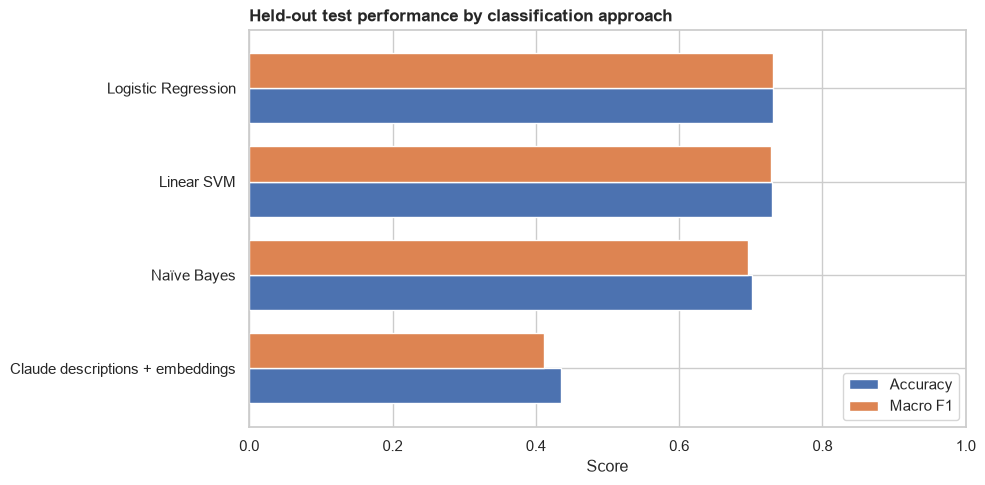

In [46]:
# Compare the main held-out test metrics visually.
plot_results = test_results[["Accuracy", "Macro F1"]].sort_values("Macro F1")
ax = plot_results.plot(kind="barh", figsize=(10, 5), width=0.75)
ax.set(title="Held-out test performance by classification approach", xlabel="Score", ylabel="")
ax.set_xlim(0, 1)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "heldout_model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

# Export numerical results for group integration.
test_results.to_csv(OUTPUT_DIR / "model_test_metrics.csv", index_label="Model")

In [47]:
# Run-specific interpretation: never hard-code the winning model.
leader = test_results.index[0]
print(f"Best held-out macro F1: {leader} ({test_results.loc[leader, 'Macro F1']:.3f})")
print(f"Its held-out accuracy: {test_results.loc[leader, 'Accuracy']:.3f}")
print("All evaluated approaches:", ", ".join(test_results.index))

Best held-out macro F1: Logistic Regression (0.731)
Its held-out accuracy: 0.731
All evaluated approaches: Logistic Regression, Linear SVM, Naïve Bayes, Claude descriptions + embeddings


### Interpretation: Held-Out Classification Performance

The table and chart above report the current held-out accuracy and macro F1 for **all models actually executed**. The Claude-description approach is generated using category labels only, not sampled narratives. Compare its observed performance with the TF-IDF classifiers; the model ranking is calculated from the outputs rather than assumed in advance.

### 3.9 Error Analysis and Confusion Matrices

Confusion matrices reveal which financial products are frequently confused. Row-normalized values indicate the share of actual complaints in each product predicted into each category. We also inspect per-class precision, recall, and F1 to avoid relying on overall accuracy alone. Any displayed complaint excerpts are kept out of exported files to reduce the risk of disclosing personal information.

Best available model by held-out macro F1: Logistic Regression


,precision,recall,f1-score,support
Debt or credit management,0.684685,0.562963,0.617886,135.0
Debt collection,0.687500,0.611111,0.647059,126.0
Checking or savings account,0.634483,0.671533,0.652482,137.0
"Payday loan, title loan, personal loan, or advance loan",0.662069,0.705882,0.683274,136.0
Credit card,0.707692,0.676471,0.691729,136.0
"Money transfer, virtual currency, or money service",0.680556,0.720588,0.700000,136.0
Prepaid card,0.715328,0.720588,0.717949,136.0
Credit reporting or other personal consumer reports,0.648485,0.899160,0.753521,119.0
Vehicle loan or lease,0.846774,0.772059,0.807692,136.0
Student loan,0.933884,0.830882,0.879377,136.0


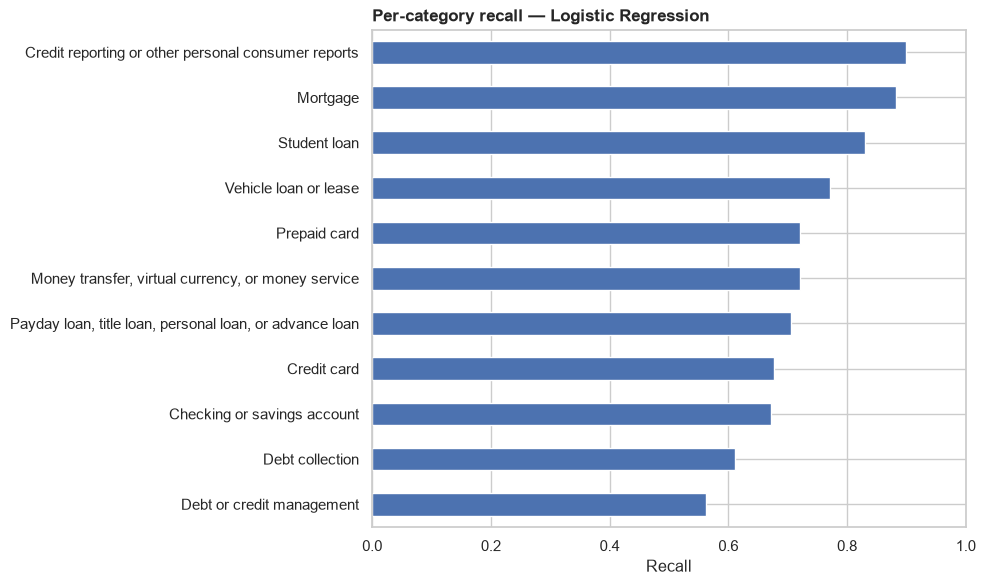

In [48]:
# Per-category performance for the highest macro-F1 model.
best_model_name = test_results.index[0]
best_predictions = model_predictions[best_model_name]
print("Best available model by held-out macro F1:", best_model_name)
report = classification_report(y_test, best_predictions, labels=all_products,
                               output_dict=True, zero_division=0)
per_category = pd.DataFrame(report).T.loc[all_products, ["precision", "recall", "f1-score", "support"]]
display(per_category.sort_values("f1-score"))

# Plot recall by product for the selected model.
ax = per_category.sort_values("recall")["recall"].plot(kind="barh", figsize=(10, 6), color=MAIN)
ax.set(title=f"Per-category recall — {best_model_name}", xlabel="Recall", ylabel="")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "per_category_recall.png", dpi=180, bbox_inches="tight")
plt.show()

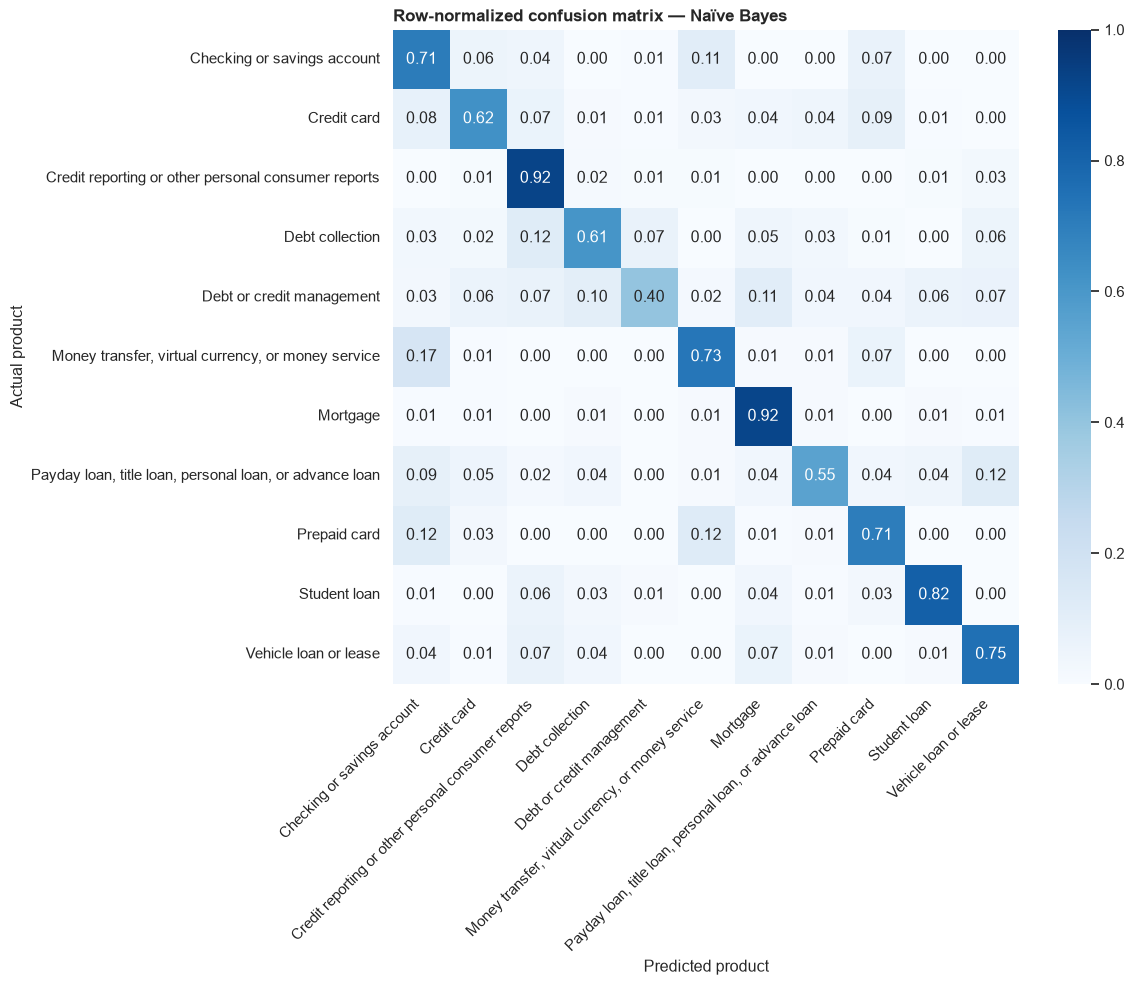

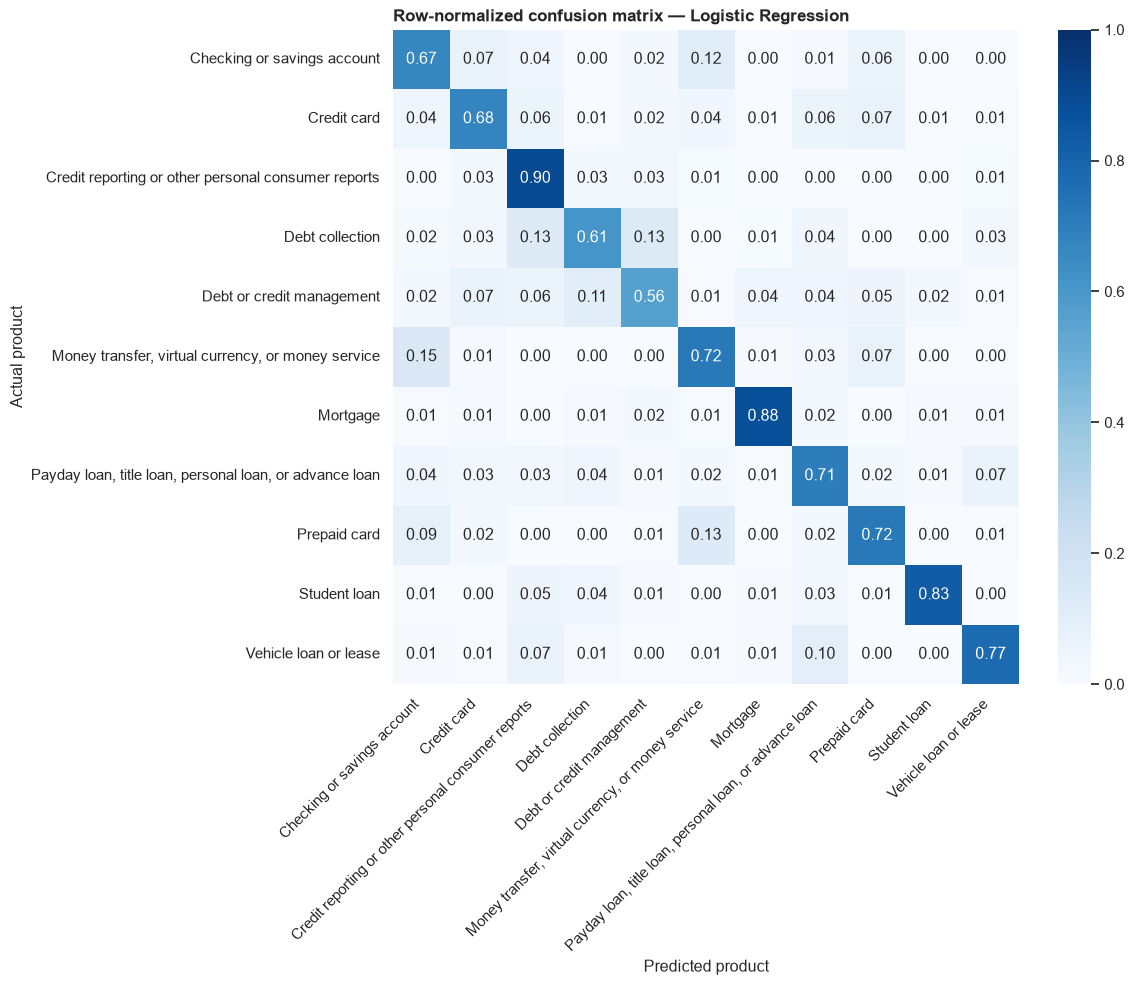

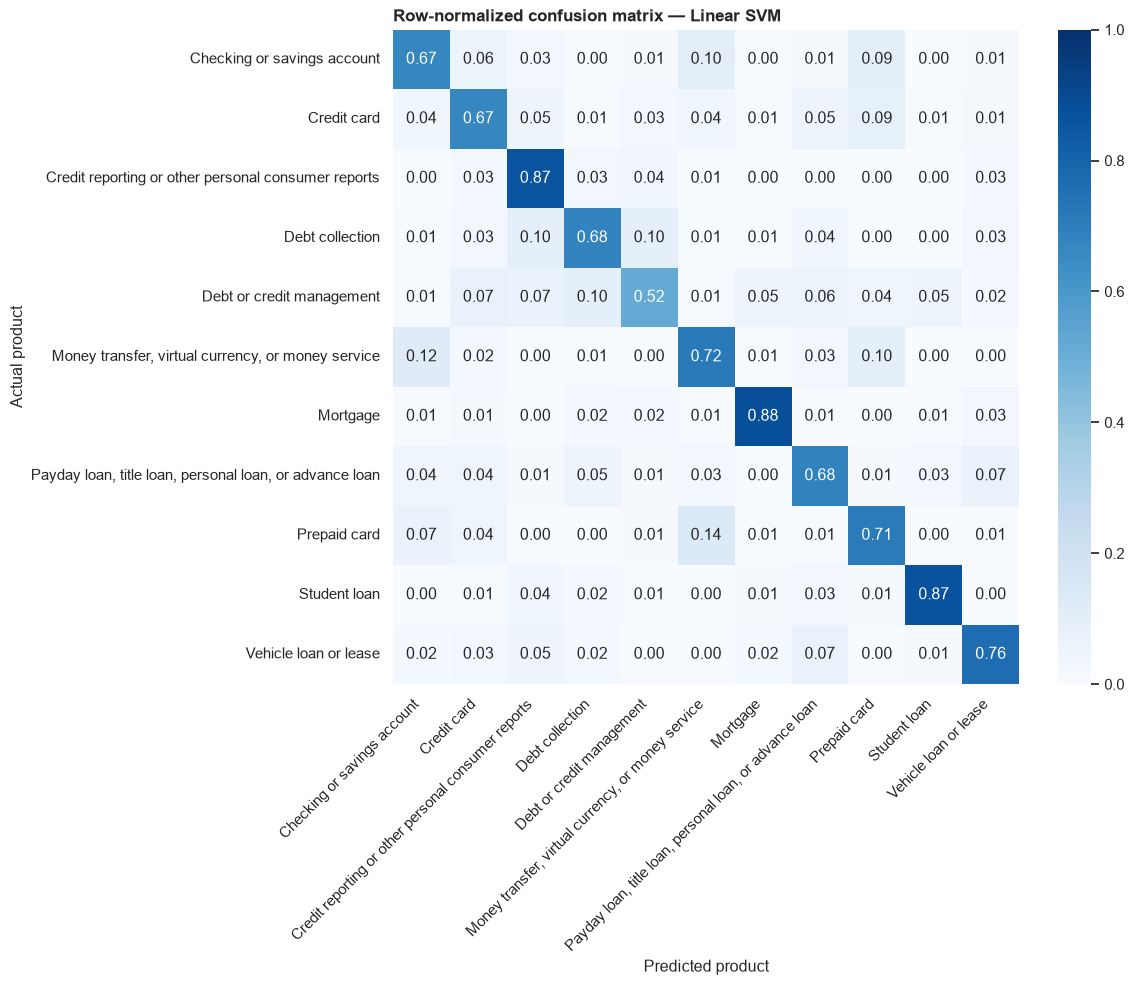

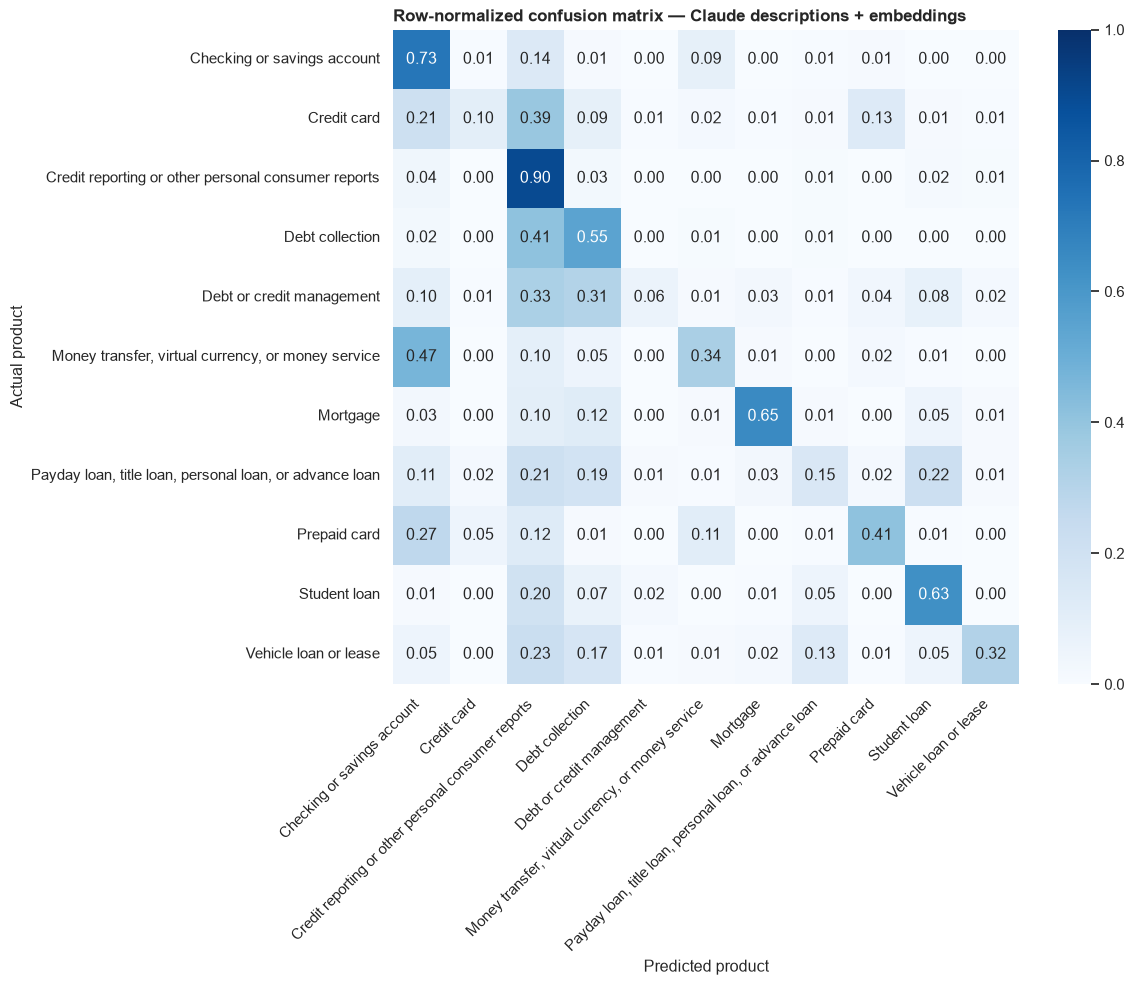

In [49]:
# Plot row-normalized confusion matrices for all evaluated models.
# Long product names are shown on both axes for interpretability.
for name, predictions in model_predictions.items():
    fig, ax = plt.subplots(figsize=(12, 10))
    matrix = confusion_matrix(y_test, predictions, labels=all_products, normalize="true")
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                xticklabels=all_products, yticklabels=all_products, ax=ax)
    ax.set(title=f"Row-normalized confusion matrix — {name}", xlabel="Predicted product", ylabel="Actual product")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    safe_name = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
    plt.savefig(OUTPUT_DIR / f"confusion_matrix_{safe_name}.png", dpi=180, bbox_inches="tight")
    plt.show()

In [50]:
# Summarize the most common off-diagonal errors without exposing narrative text.
error_matrix = confusion_matrix(y_test, best_predictions, labels=all_products)
np.fill_diagonal(error_matrix, 0)
confusions = [(all_products[i], all_products[j], int(error_matrix[i, j]))
              for i in range(len(all_products)) for j in range(len(all_products)) if error_matrix[i, j] > 0]
confusion_summary = pd.DataFrame(confusions, columns=["Actual product", "Predicted product", "Count"])
confusion_summary = confusion_summary.sort_values("Count", ascending=False).head(12)
display(confusion_summary)
confusion_summary.to_csv(OUTPUT_DIR / "top_product_confusions.csv", index=False)

,Actual product,Predicted product,Count
38,"Money transfer, virtual currency, or money service",Checking or savings account,20
64,Prepaid card,"Money transfer, virtual currency, or money service",18
24,Debt collection,Debt or credit management,17
3,Checking or savings account,"Money transfer, virtual currency, or money service",16
23,Debt collection,Credit reporting or other personal consumer reports,16
31,Debt or credit management,Debt collection,15
80,Vehicle loan or lease,"Payday loan, title loan, personal loan, or advance loan",14
61,Prepaid card,Checking or savings account,12
13,Credit card,Prepaid card,10
42,"Money transfer, virtual currency, or money service",Prepaid card,10


### Interpretation: Most Frequent Misclassifications

The confusion matrix and ranked error table above identify the most common directional misclassifications for the **best model on this run**. Examine especially product categories with overlapping financial terminology. The counts depend on the completed model comparison.

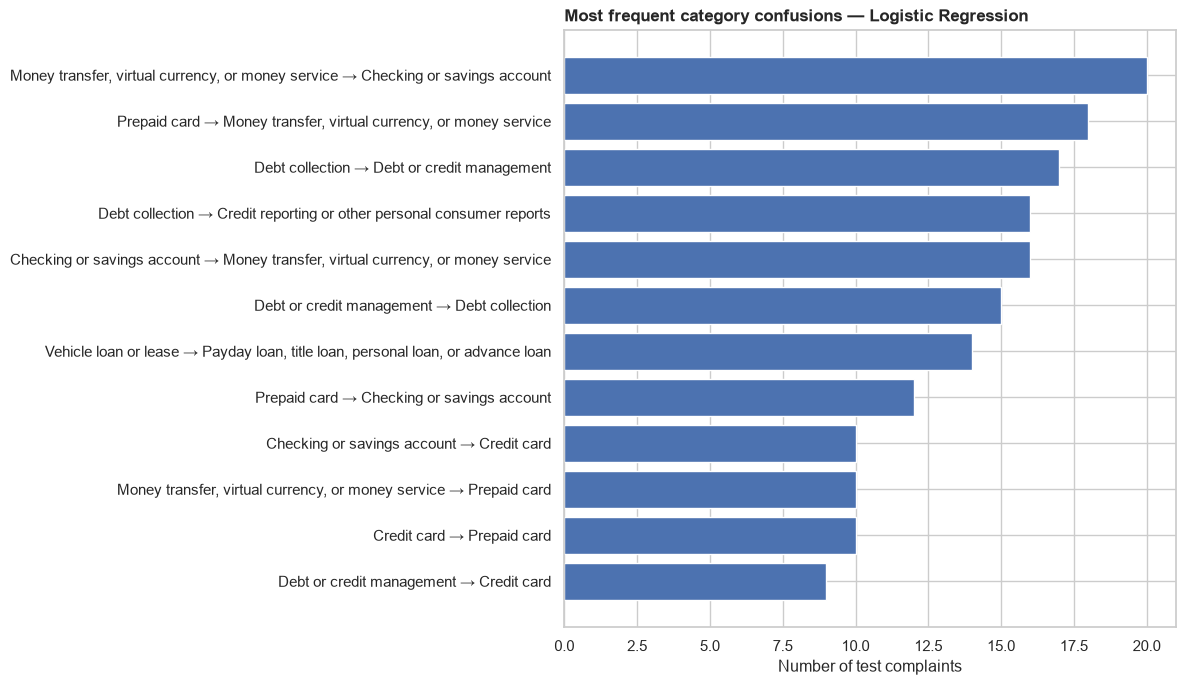

In [51]:
# Visualize the most frequent routing mistakes for the best available test-set model.
# These are directional confusions: actual product → predicted product.
plot_confusions = confusion_summary.sort_values("Count").copy()
plot_confusions["Misclassification"] = (plot_confusions["Actual product"] + " → " +
                                         plot_confusions["Predicted product"])
fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(plot_confusions["Misclassification"], plot_confusions["Count"], color=MAIN)
ax.set(title=f"Most frequent category confusions — {best_model_name}", xlabel="Number of test complaints", ylabel="")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "top_category_confusions.png", dpi=180, bbox_inches="tight")
plt.show()


### 3.10 Product-Word Masking: Robustness Experiment

Some complaints explicitly name their product (e.g., “mortgage” or “student loan”). To investigate whether classifiers depend on these obvious cues, we mask selected product-identifying phrases **in test narratives only**, without changing the trained models. This is a **distribution-shift stress test**, not a retrained-model evaluation or a causal explanation. The masking dictionary is specified in advance, applied consistently, and may remove words that have other meanings. Differences from the original test results should therefore be interpreted cautiously.

In [52]:
# Fixed, auditable list of product-identifying expressions.
# Longer phrases first avoids leaving partial product names after replacement.
PRODUCT_CUES = [
    "credit reporting", "credit report", "credit bureau", "credit card", "debt collection",
    "debt collector", "debt management", "checking account", "savings account",
    "student loan", "vehicle loan", "auto loan", "car loan", "personal loan",
    "payday loan", "money transfer", "money order", "prepaid card", "mortgage",
    "student loans", "checking", "savings", "overdraft", "escrow", "repossession"
]
PRODUCT_CUES = sorted(set(PRODUCT_CUES), key=len, reverse=True)
mask_pattern = re.compile(r"(?<!\w)(?:" + "|".join(re.escape(term) for term in PRODUCT_CUES) + r")(?!\w)", re.IGNORECASE)

def mask_product_terms(text):
    # Replace identified phrases with whitespace rather than an artificial token.
    return re.sub(r"\s+", " ", mask_pattern.sub(" ", str(text))).strip()

X_test_masked = X_test.astype(str).map(mask_product_terms)
mask_changed = (X_test_masked != X_test.astype(str)).sum()
print(f"Narratives changed by masking: {mask_changed:,} / {len(X_test_masked):,} ({mask_changed / len(X_test_masked):.1%})")
print("Cue expressions searched:", len(PRODUCT_CUES))

Narratives changed by masking: 965 / 1,469 (65.7%)
Cue expressions searched: 25


In [53]:
# Apply already-fitted models to masked text; do not refit on test data.
masked_predictions = {
    "Naïve Bayes": nb_pipeline.predict(X_test_masked),
    "Logistic Regression": lr_pipeline.predict(X_test_masked),
    "Linear SVM": svm_pipeline.predict(X_test_masked)
}
if embedding_predictions is not None:
    # Encode masked text with the exact same pretrained encoder and category vectors.
    masked_vectors = encoder.encode(X_test_masked.tolist(), normalize_embeddings=True,
                                    batch_size=32, show_progress_bar=True)
    masked_predictions["Claude descriptions + embeddings"] = np.array(all_products)[
        (masked_vectors @ description_vectors.T).argmax(axis=1)]

masked_results = pd.DataFrame({name: classification_metrics(y_test, pred)
                               for name, pred in masked_predictions.items()}).T
robustness = pd.DataFrame({
    "Original Macro F1": test_results["Macro F1"],
    "Masked Macro F1": masked_results["Macro F1"]
})
robustness["F1 Change (masked − original)"] = robustness["Masked Macro F1"] - robustness["Original Macro F1"]
display(robustness.sort_values("F1 Change (masked − original)").style.format("{:.3f}"))
robustness.to_csv(OUTPUT_DIR / "product_masking_results.csv", index_label="Model")

Batches:   0%|          | 0/46 [00:00<?, ?it/s]

,Original Macro F1,Masked Macro F1,F1 Change (masked − original)
Claude descriptions + embeddings,0.411,0.351,-0.060
Linear SVM,0.728,0.692,-0.037
Logistic Regression,0.731,0.695,-0.035
Naïve Bayes,0.696,0.673,-0.023


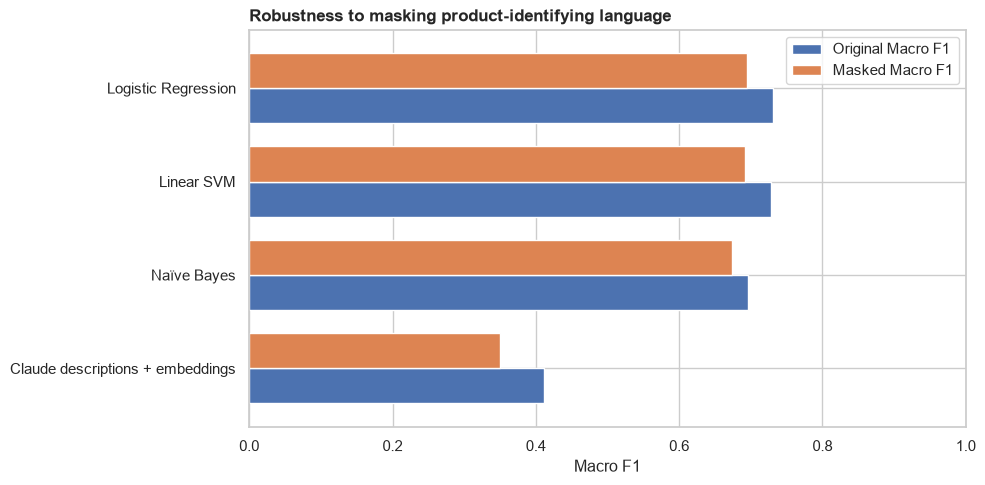

In [54]:
# Plot original versus masked macro F1 on the same scale.
ax = robustness[["Original Macro F1", "Masked Macro F1"]].sort_values("Original Macro F1").plot(
    kind="barh", figsize=(10, 5), width=0.75)
ax.set(title="Robustness to masking product-identifying language", xlabel="Macro F1", ylabel="")
ax.set_xlim(0, 1)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "masking_original_vs_masked.png", dpi=180, bbox_inches="tight")
plt.show()

### Interpretation: Sensitivity to Product-Specific Language

The robustness table and charts above show how masking product-related phrases changes macro F1 for **each evaluated model**. Negative values indicate lower performance after masking. This is a diagnostic sensitivity test, not a causal estimate.

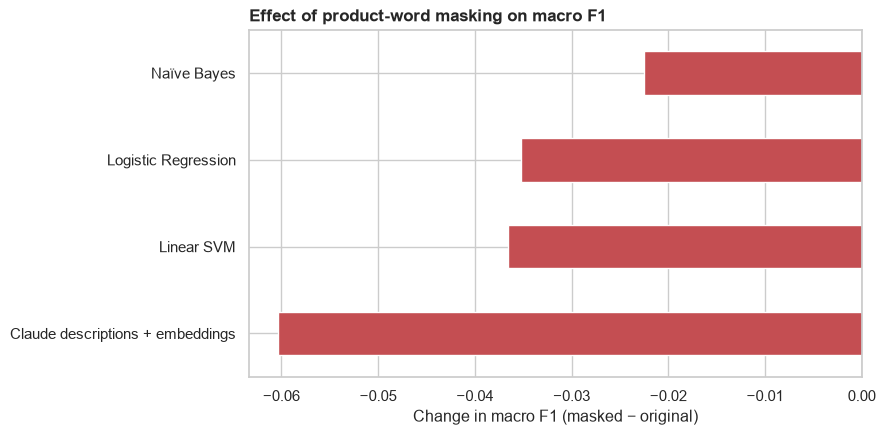

In [55]:
# Plot the reduction in macro F1 after removing product-related expressions.
# A negative change indicates lower performance on the modified test narratives.
fig, ax = plt.subplots(figsize=(9, 4.5))
robustness["F1 Change (masked − original)"].sort_values().plot(kind="barh", ax=ax, color=ACCENT)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Effect of product-word masking on macro F1", xlabel="Change in macro F1 (masked − original)", ylabel="")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "masking_f1_change.png", dpi=180, bbox_inches="tight")
plt.show()


### 3.11 Computational Efficiency and API Cost

TF-IDF models and sentence embeddings run locally. Claude is used **only to generate 11 category-label descriptions**, not to classify individual complaints. Cached descriptions avoid duplicate Claude requests. Local timing excludes network/API generation costs.

In [56]:
# Measure local prediction latency using the same held-out test set.
# These timings exclude earlier model training and notebook preprocessing.
latency_rows = []
for name, fitted in [("Naïve Bayes", nb_pipeline), ("Logistic Regression", lr_pipeline), ("Linear SVM", svm_pipeline)]:
    start = time.perf_counter()
    _ = fitted.predict(X_test)
    elapsed = time.perf_counter() - start
    latency_rows.append({"Method": name, "Test rows": len(X_test), "Inference seconds": elapsed,
                         "Milliseconds / narrative": 1000 * elapsed / len(X_test)})

if embedding_predictions is not None:
    # This elapsed time includes loading the encoder and creating embeddings.
    latency_rows.append({"Method": "Claude descriptions + embeddings", "Test rows": len(X_test),
                         "Inference seconds": embedding_elapsed,
                         "Milliseconds / narrative": 1000 * embedding_elapsed / len(X_test)})
latency_df = pd.DataFrame(latency_rows).set_index("Method")
display(latency_df.round(3))
latency_df.to_csv(OUTPUT_DIR / "inference_timing.csv")
print("Claude API generation cost: check the provider usage dashboard (not measured by this notebook).")
print("Cached descriptions:", len(category_descriptions))

,Test rows,Inference seconds,Milliseconds / narrative
Method,,,
Naïve Bayes,1469,0.142,0.096
Logistic Regression,1469,0.129,0.088
Linear SVM,1469,0.130,0.089
Claude descriptions + embeddings,1469,6.595,4.489


Claude API generation cost: check the provider usage dashboard (not measured by this notebook).
Cached descriptions: 11


### Interpretation: Computational Efficiency and Cost

Refer to the timing table above for the current run. TF-IDF inference timings and embedding timings are not perfectly comparable: the embedding time includes encoder initialization and vectorization. Claude API cost is not measured here; consult provider usage records.

### 3.12 Conclusions, Limitations, and Business Implications

This study compares supervised TF-IDF classification against a label-description embedding approach for routing CFPB complaint narratives into 11 financial product categories. **Use the computed held-out results above** to determine the strongest-performing approach; the winning method and metrics are not assumed before execution.

The Claude-assisted approach uses **only category names** to generate reference definitions. It does not send complaint narratives to Claude or train Claude on the sample. The embedding model compares these definitions with held-out complaint text locally. This design limits external exposure of consumer data, but may underperform supervised models because category definitions lack the specific vocabulary of training complaints.

Results should be interpreted as predictive rather than causal. Overlapping product terms, narrative redactions, sample selection, and distribution shifts can affect classification. The dataset's sampling design may differ from real complaint volume. Human review remains important for ambiguous or consequential routing decisions.

### 3.13 Reproducibility and Group Handoff

The notebook fixes the training/test split and sampling seeds, fits TF-IDF only on training data, caches Claude label-only category descriptions, and saves model metrics and robustness summaries in `outputs/rebecca_modelling/`. For a clean rerun, execute cells in order from the top with the project dataset and `src/` utilities available. **Do not upload `.env`, private API keys, or unreviewed narrative samples to GitHub.**

**For the team meeting:** share the final held-out comparison table, the confusion matrices, the masking experiment, and the limitations. When integrating Ketty's results, verify the same complaint IDs, category labels, train/test split, and evaluation metrics before making direct comparisons.

In [57]:
# Compact handoff summary; all figures above are computed, not hard-coded.
print("=" * 55)
print("CFPB PRODUCT CLASSIFICATION — MODELING SUMMARY")
print("=" * 55)
print(f"Train/test: {len(X_train):,} / {len(X_test):,} complaints")
print(f"Categories: {len(all_products)}")
print(f"Claude descriptions available: {len(category_descriptions)}/{len(all_products)}")
print("\nHeld-out test metrics:")
print(test_results.round(3).to_string())
print("\nMasking experiment (macro F1 change):")
print(robustness[["F1 Change (masked − original)"]].round(3).to_string())
print("\nSaved outputs:", OUTPUT_DIR)
print("Claude prompts contain category labels only; no narratives were transmitted.")

CFPB PRODUCT CLASSIFICATION — MODELING SUMMARY
Train/test: 3,426 / 1,469 complaints
Categories: 11
Claude descriptions available: 11/11

Held-out test metrics:
                                  Accuracy  Macro Precision  Macro Recall  Macro F1
Logistic Regression                  0.731            0.735         0.732     0.731
Linear SVM                           0.730            0.730         0.731     0.728
Naïve Bayes                          0.702            0.713         0.704     0.696
Claude descriptions + embeddings     0.435            0.532         0.441     0.411

Masking experiment (macro F1 change):
                                  F1 Change (masked − original)
Claude descriptions + embeddings                         -0.060
Linear SVM                                               -0.037
Logistic Regression                                      -0.035
Naïve Bayes                                              -0.023

Saved outputs: /Users/rebeccaquaye/Complex Data Analytics/Pr